# HAB 26–27 · E2

Cuaderno individual. Identificador de entrega: **COMPLETAR**.

Cierre: **06/11/2026, 02:00 Europe/Madrid**.

Este es tu documento de trabajo: explicación, código, resultados, comprobaciones e interpretación. Desarrolla el análisis con la asistencia de IA que necesites y documenta tu juicio. No se entrega un informe adicional. Consulta la pregunta y los requisitos del análisis en TAREA_ANALISIS_FUNCIONAL.html.

## Cómo trabajar sin perder secciones

Guarda una copia personal en Drive (Archivo → Guardar una copia en Drive) o en tu ordenador. Añade celdas de texto y código **debajo** de cada encabezado; no conviertas una celda con marcador en código ni borres su encabezado. Conserva una sola aparición de cada uno de los seis marcadores `E2-…`. Puedes reordenar o ampliar tu trabajo dentro de cada sección.

La carga y los controles del paquete son la única implementación proporcionada; el análisis funcional lo desarrollas tú. Las celdas vacías se ejecutan sin producir resultados.

## Cargar los datos

**Panel Archivos:** sube `airway_26-27_v1.1.zip` y deja `USAR_DRIVE=False`. Tendrás que subirlo de nuevo si se reinicia o elimina la máquina de Colab.

**Drive:** guarda el ZIP en tu Drive, pon `USAR_DRIVE=True` y ajusta `RUTA_ZIP_DRIVE` a su ubicación. Montar Drive da acceso a archivos; guardar el cuaderno es un paso distinto. No necesitas instalar paquetes para esta carga. Para reproducir la entrega debe bastar el ZIP común y una configuración de ruta documentada.


In [1]:
from pathlib import Path
# Opción A (predeterminada): sube el ZIP al panel Archivos de Colab.
# En Jupyter local, sitúa el ZIP en el directorio de trabajo.
USAR_DRIVE = False
RUTA_ZIP_DRIVE = "/content/drive/MyDrive/HAB_26-27/airway_26-27_v1.1.zip"

if USAR_DRIVE:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError("El montaje de Drive requiere Colab. En local, usa USAR_DRIVE=False.") from exc
    drive.mount("/content/drive")
    ZIP = Path(RUTA_ZIP_DRIVE)
else:
    ZIP = Path("airway_26-27_v1.1.zip")
if not ZIP.is_file():
    raise FileNotFoundError(f"No se encuentra {ZIP}. Sube el ZIP al panel Archivos o configura su ruta de Drive.")
print("Datos:", ZIP)


Datos: airway_26-27_v1.1.zip


In [2]:
import csv, json, hashlib, zipfile, io
# Integridad del paquete común. No selecciona genes ni resuelve el análisis.
with zipfile.ZipFile(ZIP) as z:
    manifests = [n for n in z.namelist() if n.endswith("/MANIFEST_SHA256.json") or n == "MANIFEST_SHA256.json"]
    if len(manifests) != 1:
        raise ValueError("El ZIP debe contener un manifiesto único.")
    prefix = manifests[0][:-len("MANIFEST_SHA256.json")]
    manifest_bytes = z.read(manifests[0])
    if hashlib.sha256(manifest_bytes).hexdigest() != "f78f1476a8bb0ea910d02ab996b027b600b024224d9bf41b7b4df9d7bded48e2":
        raise ValueError("El manifiesto no corresponde al paquete airway v1.1 del curso.")
    manifest = json.loads(manifest_bytes)
    for name, digest in manifest.items():
        if hashlib.sha256(z.read(prefix + name)).hexdigest() != digest:
            raise ValueError(f"Archivo dañado o modificado: {name}")
    de = list(csv.DictReader(io.StringIO(z.read(prefix + "expresion_diferencial.csv").decode("utf-8"))))
    samples = list(csv.DictReader(io.StringIO(z.read(prefix + "raw/samples.csv").decode("utf-8"))))
    gmt_text = z.read(prefix + "anotaciones/MSigDB_Hallmark_2020.gmt").decode("utf-8")
    diccionario = z.read(prefix + "DICCIONARIO.md").decode("utf-8")
    procedencia = json.loads(z.read(prefix + "procedencia.json"))
Path("MANIFEST_SHA256.json").write_bytes(manifest_bytes)
print({"filas_DE": len(de), "muestras": len(samples), "integridad": "hashes comprobados"})
print("Manifiesto para exportar el JSON:", Path("MANIFEST_SHA256.json").resolve())
# de y samples contienen texto CSV: convierte números, booleanos y ausencias.
# gmt_text contiene la colección; diccionario y procedencia documentan las entradas.
# Estas variables no incluyen universo, ranking ni análisis funcional resueltos.


{'filas_DE': 63677, 'muestras': 8, 'integridad': 'hashes comprobados'}
Manifiesto para exportar el JSON: /tmp/claude-0/-home-user/b8a49a32-0ac6-5399-8ed7-5bfcdf67863a/scratchpad/run7/MANIFEST_SHA256.json


## E2-pregunta_datos

Declara qué conservas y qué corriges de E1. Delimita la conclusión que vas a poner a prueba. Reincorpora las decisiones de datos, IDs, universo y el código de E1 que necesites para reproducir E2 desde el paquete común. No dependas de variables de otra sesión ni de un enlace privado a E1. Conserva una nota de evolución del trabajo.

Añade aquí tu explicación y las celdas necesarias.


### Evolución de E1: qué conservo, qué corrijo y qué pongo a prueba

En E1 hice un análisis de sobrerrepresentación (ORA) con Hallmark sobre los genes que suben y los que bajan con dexametasona. En E2 retomo una de sus conclusiones y la contrasto con la lista ordenada completa, que usa la información de todos los genes y no solo de los que pasan un corte.

#### Lo que conservo

Conservo los datos y su lectura (contraste dexametasona frente a control ajustado por línea celular, con signo positivo para lo que sube con el tratamiento), el universo de 16.122 genes evaluables, la regla de duplicados (fila de mayor `baseMean`), el espacio de símbolos y la colección Hallmark fijada del paquete. También conservo el ORA de E1 tal cual (padj < 0,05 y |log2FC| >= 1, test hipergeométrico unilateral y BH conjunta sobre 100 tests), porque es la referencia con la que comparo. Todo ese código está reincorporado en las celdas de esta sección y del método, de modo que este cuaderno se ejecuta desde el ZIP común sin haber abierto E1.

#### Lo que corrijo o cambio

En E1 escribí, como hipótesis de la conclusión 1, que en E2 el conjunto TNF-alpha "debería tener genes en los dos extremos de la lista ordenada, sin un enriquecimiento claro en un solo sentido". En la corrección de E1 se me indicó que eso debía tratarse como una hipótesis y no como un resultado obligado. Por eso aquí la formulo junto con su alternativa y fijo antes qué miraré para decidir entre ellas.

La otra corrección es de método. El ORA contaba igual que un gen sin cambio a los 60 genes de TNF-alpha con padj < 0,05 y |log2FC| < 1 (por ejemplo NFKBIA o TNFAIP3), que es una de las limitaciones de ORA que señalan Khatri et al. (2012). En E2 se usa la lista completa ordenada, sin corte.

Lo que no cambio es el tratamiento de los símbolos renombrados (CYR61/CCN1, CTGF/CCN2, IL8/CXCL8). El paquete sigue sin traer una tabla de equivalencias versionada, así que lo mantengo como límite documentado. La auditoría de abajo vuelve a mostrar los casos.

#### Conclusión de E1 que pongo a prueba

La conclusión 1 de E1 decía que "TNF-alpha Signaling via NF-kB" era el resultado más fuerte del ORA, pero entre los genes que suben (k = 26, q ≈ 1,6e-9), sostenido por genes de respuesta a glucocorticoides y reguladores como DUSP1 o PER1, y que también salía entre los que bajan (k = 15, q ≈ 0,0017) con mediadores como LIF o TNFAIP6. A partir de ahí planteo dos hipótesis que la lista ordenada puede distinguir:

- H1 (la predicción de E1): como el conjunto tiene genes que suben y genes que bajan, GSEA dará una señal débil o repartida, con un NES pequeño o no significativo.
- H2 (la alternativa): los genes que suben dominan, y GSEA dará un NES positivo y significativo cuyo leading edge contenga los genes de respuesta a glucocorticoides.

Para decidir miraré el signo del NES y su FDR (con el mismo nivel 0,05 que en E1), qué genes forman el leading edge y cuánto baja la curva de enriquecimiento en el otro extremo, que es lo que indicaría una señal repartida. Como la conclusión 3 de E1 aplicaba el mismo razonamiento a los otros cinco conjuntos que salieron en las dos direcciones, en la comparación también los reviso, aunque la conclusión que contrasto es la de TNF-alpha.

#### Nota de evolución del trabajo

- E1 (entregada el 24/10/2026): ORA con universo de 16.122 genes y 25 resultados significativos.
- E2, primer paso: reincorporar la carga, el universo y el ORA de E1 y comprobar que se reproducen los mismos números (lo comprueban los `assert` del método).
- E2, segundo paso: construir el ranking completo y ejecutar GSEA preranked. Uso 1.000 permutaciones, el valor por defecto de gseapy, y en la sección de reproducibilidad documento lo que eso supone: repito el análisis con la misma semilla (sale idéntico) y con otra semilla (para ver cuánto varían las FDR).
- E2, tercer paso: leading edge, comparación con ORA, las dos comprobaciones de robustez y la síntesis.

In [3]:
# Instalación: se hace antes de cualquier import del análisis.
# gseapy no viene instalado en Colab; se fija la versión para que el resultado sea reproducible.
# pandas, numpy, scipy, statsmodels y matplotlib ya vienen en Colab (en Jupyter local: pip install ...).
%pip install -q gseapy==1.3.2


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [4]:
import math, sys, io, zipfile, hashlib, datetime, platform, logging
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
from statsmodels.stats.multitest import multipletests
import matplotlib
import matplotlib.pyplot as plt
import gseapy

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 220)
Path('resultados').mkdir(exist_ok=True)

# Parámetros de todo el análisis en un mismo sitio
PARAMETROS = {
    # Heredados de E1 (universo, duplicados y ORA de comparación)
    'duplicados': 'por símbolo se conserva la fila con mayor baseMean (empate: menor gene_id)',
    'coleccion': 'MSigDB_Hallmark_2020 (snapshot del paquete, 50 conjuntos)',
    'umbral_padj_gen': 0.05,
    'umbral_abs_log2FC': 1.0,
    'alfa_funcional': 0.05,
    # Nuevos de E2 (lista ordenada)
    'estadistico_ranking': 'stat (Wald firmado de PyDESeq2); positivo = más expresión con dexametasona',
    'empates': 'orden por stat decreciente y, si hay empate, por símbolo alfabético',
    'metodo_gsea': 'gseapy.prerank, permutación de genes (method="permutation")',
    'weight': 1.0,
    'min_size': 15,
    'max_size': 500,
    'permutaciones': 1000,
    'semilla': 2026,
    'hilos': 2,
}
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__,
      '| scipy', scipy.__version__, '| statsmodels', statsmodels.__version__,
      '| matplotlib', matplotlib.__version__, '| gseapy', gseapy.__version__)
for k, v in PARAMETROS.items():
    print(f'{k}: {v}')

Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | scipy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.11.2 | gseapy 1.3.2
duplicados: por símbolo se conserva la fila con mayor baseMean (empate: menor gene_id)
coleccion: MSigDB_Hallmark_2020 (snapshot del paquete, 50 conjuntos)
umbral_padj_gen: 0.05
umbral_abs_log2FC: 1.0
alfa_funcional: 0.05
estadistico_ranking: stat (Wald firmado de PyDESeq2); positivo = más expresión con dexametasona
empates: orden por stat decreciente y, si hay empate, por símbolo alfabético
metodo_gsea: gseapy.prerank, permutación de genes (method="permutation")
weight: 1.0
min_size: 15
max_size: 500
permutaciones: 1000
semilla: 2026
hilos: 2


### Datos, contraste y alcance (se conservan de E1)

Los datos son los del paquete `hab-airway-26-27-v1.1` (a partir de `airway 1.32.0`; Himes et al., 2014; GEO GSE52778), con la tabla de expresión diferencial calculada con PyDESeq2 y el diseño `~cell + dex`. El contraste es dexametasona frente a control ajustado por línea celular, así que un valor positivo de `log2FoldChange` o de `stat` significa más expresión con el tratamiento. Hay 4 líneas celulares con una muestra tratada y otra control cada una: la unidad experimental es la línea celular y no son 8 pacientes independientes. La celda siguiente lo vuelve a leer del propio paquete.

In [5]:
campos = ['package_id', 'source_package', 'study_doi', 'geo', 'design', 'contrast', 'positive_effect',
          'prefilter', 'software', 'gene_p_adjustment', 'annotation', 'collection', 'rows', 'tested_rows']
for c in campos:
    print(f'{c}: {procedencia[c]}')
muestras = pd.DataFrame(samples).rename(columns={'': 'muestra'})
print()
print(muestras[['muestra', 'cell', 'dex']].to_string(index=False))
assert (pd.crosstab(muestras['cell'], muestras['dex']) == 1).all().all(), 'No hay exactamente un par por línea'

package_id: hab-airway-26-27-v1.1
source_package: airway 1.32.0
study_doi: 10.1371/journal.pone.0099625
geo: GSE52778
design: ~cell + dex
contrast: ['dex', 'trt', 'untrt']
positive_effect: dexamethasone > untreated
prefilter: counts >= 10 in >= 4 of 8 samples
software: PyDESeq2 0.5.4; Python 3.12.10; R 4.2.1 extraction
gene_p_adjustment: Benjamini-Hochberg over 16139 tested genes
annotation: Embedded airway annotation; Ensembl GRCh37 release 75 provenance; not current HGNC
collection: MSigDB_Hallmark_2020 (Enrichr snapshot; exact MSigDB release unspecified by endpoint)
rows: 63677
tested_rows: 16139

   muestra    cell   dex
SRR1039508  N61311 untrt
SRR1039509  N61311   trt
SRR1039512 N052611 untrt
SRR1039513 N052611   trt
SRR1039516 N080611 untrt
SRR1039517 N080611   trt
SRR1039520 N061011 untrt
SRR1039521 N061011   trt


#### Conversión de la tabla y auditoría (código de E1)

Repito la conversión explícita de E1: los campos vacíos pasan a NaN y nunca a 0, los booleanos se convierten a mano y se comprueba que las ausencias coinciden con los genes que no pasaron el prefiltro. También vuelvo a comprobar que `stat` es `log2FoldChange / lfcSE`, porque ahora `stat` es el estadístico con el que voy a ordenar los genes.

In [6]:
tabla = pd.DataFrame(de)
NUMERICAS = ['baseMean', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue', 'padj']

def a_numero(valor):
    return np.nan if valor == '' else float(valor)

for col in NUMERICAS:
    tabla[col] = tabla[col].map(a_numero).astype(float)
assert set(tabla['prefilter_pass']) <= {'True', 'False'}
tabla['prefilter_pass'] = tabla['prefilter_pass'].map({'True': True, 'False': False}).astype(bool)

probados = tabla['test_status'] == 'tested'
print('Filas:', len(tabla), '| gene_id únicos:', tabla['gene_id'].is_unique)
print(tabla['test_status'].value_counts().to_string())
assert tabla.loc[probados, NUMERICAS].notna().all().all()
assert tabla.loc[~probados, NUMERICAS].isna().all().all()
assert (tabla['prefilter_pass'] == probados).all()
t_ = tabla[probados]
assert np.allclose(t_['stat'], t_['log2FoldChange'] / t_['lfcSE'], rtol=1e-7, atol=1e-9)
print('OK: ausencias solo en genes no probados y stat = log2FC / lfcSE en los', probados.sum(), 'genes probados')

Filas: 63677 | gene_id únicos: True
test_status
low_count    47538
tested       16139
OK: ausencias solo en genes no probados y stat = log2FC / lfcSE en los 16139 genes probados


In [7]:
# Colección Hallmark del paquete (no se cambia la versión fijada)
conjuntos = {}
for linea in gmt_text.splitlines():
    if not linea.strip():
        continue
    campos_gmt = linea.split('\t')
    genes = [g for g in campos_gmt[2:] if g]
    assert len(genes) == len(set(genes))
    conjuntos[campos_gmt[0]] = set(genes)
simbolos_coleccion = set().union(*conjuntos.values())
print('Conjuntos:', len(conjuntos), '| símbolos distintos en la colección:', len(simbolos_coleccion))

# Auditoría de identificadores de E1: duplicados y símbolos del GMT sin fila en la anotación
solo_probados = tabla[probados]
dup = solo_probados[solo_probados['symbol'].duplicated(keep=False)]
print('Genes probados con símbolo repetido:', len(dup), 'filas,', dup['symbol'].nunique(), 'símbolos;',
      'de ellos en Hallmark:', ', '.join(sorted(set(dup['symbol']) & simbolos_coleccion)))
ausentes_anotacion = sorted(simbolos_coleccion - set(tabla['symbol']))
print('Símbolos de Hallmark sin ninguna fila en la anotación:', len(ausentes_anotacion))
print('Posibles nombres antiguos en la tabla:')
print(tabla.loc[tabla['symbol'].isin(['CYR61', 'CTGF', 'IL8']), ['gene_id', 'symbol', 'stat', 'padj']].to_string(index=False))
for nuevo_nombre in ['CCN1', 'CCN2', 'CXCL8']:
    print(f'  {nuevo_nombre} en el GMT:', ', '.join(k for k, v in conjuntos.items() if nuevo_nombre in v))

Conjuntos: 50 | símbolos distintos en la colección: 4383
Genes probados con símbolo repetido: 29 filas, 12 símbolos; de ellos en Hallmark: CKS1B, IDS, SRSF10
Símbolos de Hallmark sin ninguna fila en la anotación: 119
Posibles nombres antiguos en la tabla:
        gene_id symbol      stat         padj
ENSG00000118523   CTGF  5.643443 2.810972e-07
ENSG00000142871  CYR61  5.718297 1.865205e-07
ENSG00000169429    IL8 -0.163267 9.400308e-01
  CCN1 en el GMT: TNF-alpha Signaling via NF-kB, Hypoxia, Epithelial Mesenchymal Transition, UV Response Dn
  CCN2 en el GMT: Hypoxia, Epithelial Mesenchymal Transition
  CXCL8 en el GMT: Epithelial Mesenchymal Transition, Inflammatory Response


#### Universo (igual que en E1)

El universo son los genes evaluables: `test_status == tested`, con `pvalue`, `padj` y `log2FoldChange` finitos, símbolo no vacío y una sola fila por símbolo (la de mayor `baseMean`, y si hay empate la de menor `gene_id`). Ningún paso usa la significación ni el signo. En E2 este mismo conjunto de genes es a la vez el universo del ORA y la lista que se ordena para GSEA, así que los dos métodos parten exactamente de los mismos genes.

In [8]:
pasos = []
u = tabla.copy()
pasos.append(('Filas de la tabla', len(u)))
u = u[u['test_status'] == 'tested']
pasos.append(('test_status == tested', len(u)))
u = u[np.isfinite(u['pvalue']) & np.isfinite(u['padj']) & np.isfinite(u['log2FoldChange'])]
pasos.append(('p, padj y log2FC finitos', len(u)))
u = u[u['symbol'] != '']
pasos.append(('símbolo no vacío', len(u)))
u = (u.sort_values(['symbol', 'baseMean', 'gene_id'], ascending=[True, False, True])
       .drop_duplicates('symbol', keep='first'))
pasos.append(('una fila por símbolo (mayor baseMean)', len(u)))
universo = u.set_index('symbol')
print(pd.DataFrame(pasos, columns=['paso', 'filas']).to_string(index=False))
assert universo.index.is_unique and np.isfinite(universo['stat']).all()
print('\nN =', len(universo), '| con algún conjunto Hallmark:', universo.index.isin(list(simbolos_coleccion)).sum())

                                 paso  filas
                    Filas de la tabla  63677
                test_status == tested  16139
             p, padj y log2FC finitos  16139
                     símbolo no vacío  16139
una fila por símbolo (mayor baseMean)  16122

N = 16122 | con algún conjunto Hallmark: 3423


#### Integridad del signo (comprobación de E1)

Como GSEA va a leer la lista desde los genes que más suben hasta los que más bajan, un signo invertido daría la vuelta a todo. Repito la prueba de E1: a partir de los recuentos crudos del mismo ZIP calculo un cambio por pares muy simple (log2 CPM tratado menos control en cada línea) y miro si su signo coincide con el de la tabla en los genes que más cambian. Invertir las etiquetas a propósito sirve de control de que la prueba detectaría el fallo.

In [9]:
with zipfile.ZipFile(ZIP) as z:
    nombre_counts = [x for x in z.namelist() if x.endswith('raw/counts.csv')][0]
    recuentos = pd.read_csv(io.BytesIO(z.read(nombre_counts)), index_col=0)
assert list(recuentos.columns) == list(muestras['muestra'])
log_cpm = np.log2(recuentos / recuentos.sum() * 1e6 + 1)
m = muestras.set_index('muestra')

def concordancia(etiquetas):
    sel = tabla.loc[(tabla['padj'] < 0.05) & (tabla['log2FoldChange'].abs() >= 1), ['gene_id', 'log2FoldChange']]
    pares = []
    for c in m['cell'].unique():
        st = [s for s in m.index if m.loc[s, 'cell'] == c and etiquetas[s] == 'trt'][0]
        su = [s for s in m.index if m.loc[s, 'cell'] == c and etiquetas[s] == 'untrt'][0]
        pares.append(log_cpm[st] - log_cpm[su])
    crudo = pd.concat(pares, axis=1).mean(axis=1).loc[sel['gene_id']]
    return np.mean(np.sign(crudo.values) == np.sign(sel['log2FoldChange'].values))

conc = concordancia(m['dex'])
conc_inv = concordancia(m['dex'].map({'trt': 'untrt', 'untrt': 'trt'}))
print(f'Concordancia de signo con los recuentos crudos: {conc:.1%} | con etiquetas invertidas: {conc_inv:.1%}')
assert conc > 0.95

Concordancia de signo con los recuentos crudos: 100.0% | con etiquetas invertidas: 0.0%


## E2-metodo

Construye una lista ordenada de todos los genes elegibles, sin recortarla a significativos. Justifica estadístico, signo, duplicados, empates, colección, pesos, tamaños de conjuntos, procedimiento nulo, permutaciones, semilla y corrección. Implementa GSEA/preranked o una alternativa equivalente justificada. Conserva ranking, tabla completa y genes que sostienen el resultado (leading edge o equivalente). Incluye el ORA necesario para comparar. Una permutación de genes/conjuntos no equivale a permutar pacientes.

Añade aquí tu explicación y las celdas necesarias.


### Decisiones del método y por qué

#### Estadístico del ranking y signo

Ordeno los genes por la columna `stat`, el estadístico de Wald firmado de PyDESeq2, de mayor a menor. Su signo es el del `log2FoldChange` (se ha comprobado arriba que `stat = log2FC / lfcSE`), así que arriba quedan los genes que más suben con dexametasona y abajo los que más bajan. Lo prefiero al `log2FoldChange` porque el diccionario del paquete indica que ese log2FC es una estimación sin contraer (sin shrinkage): en genes con pocos recuentos puede ser muy grande solo por ruido, mientras que `stat` lo divide por su error estándar y tiene en cuenta la incertidumbre. Tampoco uso -log10(p) con signo, porque el p del test de Wald depende solo de |stat| y ordenaría los genes igual, salvo los p tan pequeños que se redondean y dejarían empates. Que el estadístico sea una decisión con alternativas razonables es justo lo que pongo a prueba en la comprobación A.

#### Genes incluidos, duplicados y empates

La lista contiene los 16.122 genes del universo, sin recortar a significativos, porque GSEA necesita ver también los genes que apenas cambian para saber si los de un conjunto se concentran en un extremo. Los duplicados de símbolo ya están resueltos con la regla de E1, que no depende de la significación. Para los empates de `stat` uso un criterio determinista: si dos genes tienen el mismo valor, se ordenan por símbolo. La celda siguiente muestra que solo hay 9 genes empatados (histonas, pseudogenes RN7SL y ABHD17AP, con los mismos recuentos) y que ninguno está en Hallmark, así que el orden entre ellos no puede afectar a ningún conjunto. Paso la lista ya ordenada a gseapy con `ascending=None`, que según su documentación no reordena la lista, y lo compruebo con un `assert`. gseapy sigue mostrando un aviso de valores duplicados, que por lo anterior no tiene consecuencias aquí.

#### Colección, tamaños y peso

Se usa el mismo GMT del paquete (`MSigDB_Hallmark_2020`, 50 conjuntos), pasado como diccionario para no descargar ninguna biblioteca remota. Uso `min_size = 15` y `max_size = 500`, los valores por defecto de gseapy, que se refieren a los genes del conjunto presentes en la lista. Con ellos no se excluye ningún conjunto, porque el más pequeño tiene 19 genes en los datos y el mayor 195. El peso es `weight = 1`, el GSEA ponderado de Subramanian et al. (2005): cada gen del conjunto suma en la curva en proporción a su `stat`, de forma que pesan más los genes que cambian mucho. Con `weight = 0` se volvería a un estadístico de Kolmogorov-Smirnov sin pesos, que no uso.

#### Modelo nulo, permutaciones y semilla

GSEA preranked no puede permutar las etiquetas de las muestras, porque parte de un ranking ya calculado. gseapy construye la distribución nula permutando los genes, que equivale a sacar conjuntos aleatorios del mismo tamaño de la misma lista y calcular su ES. Esto no es lo mismo que permutar muestras: al barajar genes se rompen las correlaciones entre los genes de un conjunto (lo advierte la guía de lecturas sobre Subramanian et al., 2005), y como los genes de un mismo programa suelen variar juntos, es de esperar que la p resultante sea optimista. Permutar muestras aquí tampoco sería una opción real: el contraste está emparejado por línea celular y con 4 pares solo hay 2^4 = 16 formas de intercambiar tratamiento y control dentro de cada par, lo que no permitiría una p menor de 1/16, y además habría que rehacer la expresión diferencial en cada permutación, que el enunciado no pide.

Uso 1.000 permutaciones y la semilla 2026. Con 1.000 permutaciones la p nominal más pequeña que se puede estimar es 0,001, y una p de 0,05 tiene un error de muestreo aproximado de raíz(0,05 x 0,95 / 1.000) ≈ 0,007. Esto basta para el conjunto que contrasto, pero los valores de FDR cercanos a 0,05 hay que leerlos con prudencia. Fijar la semilla hace que la ejecución sea repetible.

#### Corrección múltiple

No aplico BH sobre las p nominales. Uso la FDR q propia de GSEA, que compara el NES de cada conjunto con los NES nulos de todos los conjuntos, por separado para los NES positivos y los negativos, y por eso tiene en cuenta que se evalúan 50 conjuntos a la vez. Considero significativo FDR q < 0,05, el mismo nivel que en el ORA de E1, para que la comparación sea justa. También se guarda la FWER p, que es más estricta. El NES es la ES dividida por la media de las ES nulas del mismo signo, y es lo que permite comparar conjuntos de distinto tamaño.

#### ORA para comparar

El ORA es el de E1 sin ningún cambio, recalculado en este cuaderno. Así la comparación cambia solo el método (lista seleccionada frente a lista ordenada) y no los datos, el universo ni la colección.

In [10]:
# Ranking completo: los 16.122 genes del universo, sin recortar a significativos
ranking = (universo.reset_index()[['symbol', 'gene_id', 'baseMean', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue', 'padj']]
           .sort_values(['stat', 'symbol'], ascending=[False, True]).reset_index(drop=True))
ranking.insert(0, 'posicion', np.arange(1, len(ranking) + 1))
assert len(ranking) == len(universo) and ranking['symbol'].is_unique
assert ranking['stat'].is_monotonic_decreasing

empatados = ranking[ranking['stat'].duplicated(keep=False)]
print('Genes en la lista:', len(ranking), '| con stat > 0:', (ranking['stat'] > 0).sum(), '| con stat < 0:', (ranking['stat'] < 0).sum())
print('Genes con el mismo valor de stat que otro gen:', len(empatados),
      '| de ellos en Hallmark:', empatados['symbol'].isin(list(simbolos_coleccion)).sum())
print(empatados[['posicion', 'symbol', 'gene_id', 'stat', 'baseMean']].to_string(index=False))
ranking.to_csv('resultados/E2_ranking_stat.csv', index=False, float_format='%.17g')
print('\nPrincipio y final de la lista ordenada:')
print(pd.concat([ranking.head(8), ranking.tail(8)])[['posicion', 'symbol', 'stat', 'log2FoldChange', 'padj']]
      .to_string(index=False, float_format=lambda x: f'{x:.3g}'))

Genes en la lista: 16122 | con stat > 0: 7855 | con stat < 0: 8267
Genes con el mismo valor de stat que otro gen: 9 | de ellos en Hallmark: 0
 posicion    symbol         gene_id      stat   baseMean
     8523  HIST2H3A ENSG00000203852 -0.177918  10.298808
     8524  HIST2H3C ENSG00000203811 -0.177918  10.298808
     8977 ABHD17AP1 ENSG00000203835 -0.294859 147.077849
     8978 ABHD17AP2 ENSG00000198658 -0.294859 147.077849
    13088 RN7SL256P ENSG00000241500 -1.685382  14.518762
    13089 RN7SL410P ENSG00000243464 -1.685382  14.518762
    13090  RN7SL61P ENSG00000240994 -1.685382  14.518762
    14798  HIST2H4A ENSG00000183941 -3.013923 158.457447
    14799  HIST2H4B ENSG00000182217 -3.013923 158.457447



Principio y final de la lista ordenada:
 posicion  symbol  stat  log2FoldChange      padj
        1 SPARCL1  27.5            4.57 4.52e-162
        2  SAMHD1  27.2            3.76 1.88e-158
        3    MAOA  25.6            3.35 6.79e-141
        4    GPX3  25.5            3.73 1.05e-139
        5   DUSP1  25.3            2.94 2.25e-137
        6  CACNB2  23.7            3.29 1.47e-120
        7   KLF15  21.6            4.46 5.23e-100
        8    PER1  21.1            3.19  7.38e-96
    16115    WNT2 -16.7           -3.05  6.57e-60
    16116  ADAM12   -17           -1.82  2.84e-62
    16117  PRSS35 -17.5           -2.76  5.92e-66
    16118   CCKAR -17.7           -2.19  3.96e-67
    16119    SOX4 -18.3           -2.41  1.52e-71
    16120  CXCL12 -18.3           -1.92  6.82e-72
    16121  KCTD12 -20.1           -2.53  6.27e-87
    16122   VCAM1 -21.1           -3.69  1.61e-95


In [11]:
gene_sets = {k: sorted(v) for k, v in conjuntos.items()}   # el GMT del paquete, sin biblioteca remota
TNF = 'TNF-alpha Signaling via NF-kB'

def ejecutar_gsea(tabla_rank, columna, permutaciones=PARAMETROS['permutaciones'], semilla=PARAMETROS['semilla']):
    # La lista se pasa ya ordenada y ascending=None hace que gseapy no la reordene,
    # de modo que los empates quedan resueltos con la regla declarada (orden alfabético).
    rnk = tabla_rank[['symbol', columna]].reset_index(drop=True)
    assert rnk[columna].is_monotonic_decreasing
    pre = gseapy.prerank(rnk=rnk, gene_sets=gene_sets, min_size=PARAMETROS['min_size'],
                         max_size=PARAMETROS['max_size'], permutation_num=permutaciones,
                         weight=PARAMETROS['weight'], ascending=None, seed=semilla,
                         threads=PARAMETROS['hilos'], method='permutation', no_plot=True, outdir=None)
    assert list(pre.ranking.index) == list(rnk['symbol']), 'gseapy ha cambiado el orden de la lista'
    res = pre.res2d.rename(columns={'Term': 'conjunto', 'NOM p-val': 'p_nominal', 'FDR q-val': 'FDR_q',
                                    'FWER p-val': 'FWER_p', 'Lead_genes': 'leading_edge'})
    res['n_leading_edge'] = res['Tag %'].str.split('/').str[0].astype(int)
    res['n_en_datos'] = res['Tag %'].str.split('/').str[1].astype(int)
    for c in ['ES', 'NES', 'p_nominal', 'FDR_q', 'FWER_p']:
        res[c] = res[c].astype(float)
    res = res.drop(columns=['Name']).set_index('conjunto')
    return res, pre

logging.getLogger('gseapy').setLevel(logging.ERROR)  # el aviso de empates ya está tratado arriba
gsea, pre_principal = ejecutar_gsea(ranking, 'stat')
p_min = 1 / PARAMETROS['permutaciones']
gsea['p_nominal_texto'] = gsea['p_nominal'].map(lambda p: f'< {p_min:g}' if p == 0 else f'{p:.4g}')
print('Conjuntos evaluados:', len(gsea), '| tamaño en los datos: mínimo', gsea['n_en_datos'].min(),
      '| máximo', gsea['n_en_datos'].max())
print('FDR q < 0.05:', (gsea['FDR_q'] < 0.05).sum(), '| NES > 0 entre ellos:', ((gsea['FDR_q'] < 0.05) & (gsea['NES'] > 0)).sum())
print('Resultado de TNF-alpha:', gsea.loc[TNF, ['ES', 'NES', 'p_nominal_texto', 'FDR_q', 'Tag %']].to_dict())

2026-11-07 19:26:26,231 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Conjuntos evaluados: 50 | tamaño en los datos: mínimo 19 | máximo 195
FDR q < 0.05: 12 | NES > 0 entre ellos: 12
Resultado de TNF-alpha: {'ES': 0.4938980784005706, 'NES': 1.8659246044963227, 'p_nominal_texto': '< 0.001', 'FDR_q': 0.0025817817331348905, 'Tag %': '60/172'}


#### Tabla completa de GSEA

Se conservan los 50 conjuntos, también los no significativos. Una `p_nominal` de 0 en la salida de gseapy quiere decir que ninguna de las 1.000 permutaciones igualó la ES observada, así que en la columna de texto se escribe como `< 0.001`, que es la precisión real de la estimación. La tabla con los genes del leading edge de cada conjunto y los valores a precisión completa se guarda en `resultados/E2_GSEA_hallmark_completa.csv`.

In [12]:
gsea = gsea.sort_values('NES', ascending=False)
gsea.reset_index().to_csv('resultados/E2_GSEA_hallmark_completa.csv', index=False, float_format='%.17g')
vista = gsea[['ES', 'NES', 'p_nominal_texto', 'FDR_q', 'FWER_p', 'n_en_datos', 'n_leading_edge', 'Gene %']].copy()
vista['ES'] = vista['ES'].round(3); vista['NES'] = vista['NES'].round(3)
vista['FDR_q'] = vista['FDR_q'].map(lambda x: f'{x:.3g}'); vista['FWER_p'] = vista['FWER_p'].map(lambda x: f'{x:.3g}')
vista

,ES,NES,p_nominal_texto,FDR_q,FWER_p,n_en_datos,n_leading_edge,Gene %
conjunto,,,,,,,,
Adipogenesis,0.501,1.914,< 0.001,0.00103,0.001,181,57,14.86%
TNF-alpha Signaling via NF-kB,0.494,1.866,< 0.001,0.00258,0.005,172,60,9.94%
Androgen Response,0.513,1.774,< 0.001,0.0031,0.009,88,33,12.15%
Xenobiotic Metabolism,0.439,1.632,< 0.001,0.0188,0.07,149,57,17.24%
Reactive Oxygen Species Pathway,0.537,1.631,0.003515,0.0155,0.072,45,10,6.75%
UV Response Dn,0.443,1.627,< 0.001,0.0138,0.077,137,40,10.48%
Fatty Acid Metabolism,0.440,1.618,< 0.001,0.0142,0.091,131,37,15.65%
IL-2/STAT5 Signaling,0.427,1.584,0.001449,0.0182,0.131,153,44,10.35%
Complement,0.416,1.546,0.006107,0.025,0.194,139,44,16.23%


#### ORA de E1, reconstruido aquí para poder comparar

Para comparar no enlazo E1: repito su ORA con el mismo código y los mismos parámetros (padj < 0,05 y |log2FC| >= 1, test hipergeométrico unilateral y BH conjunta sobre 50 conjuntos por 2 direcciones). Si todo está bien deben salir otra vez 493 genes que suben, 464 que bajan y 25 resultados significativos.

In [13]:
def bh(pvalores):
    p = np.asarray(pvalores, dtype=float)
    m_ = len(p)
    orden = np.argsort(p)
    ajust = p[orden] * m_ / np.arange(1, m_ + 1)
    ajust = np.minimum.accumulate(ajust[::-1])[::-1]
    q = np.empty(m_)
    q[orden] = np.minimum(ajust, 1.0)
    return q


def ora(universo_simbolos, seleccion_por_direccion, conjuntos, lfc):
    U = set(universo_simbolos)
    N = len(U)
    filas = []
    for direccion, sel in seleccion_por_direccion.items():
        sel = set(sel) & U
        n = len(sel)
        for nombre, genes in conjuntos.items():
            enU = genes & U
            K = len(enU)
            sol = sorted(enU & sel, key=lambda g: -abs(lfc[g]))
            k = len(sol)
            filas.append({'direccion': direccion, 'conjunto': nombre, 'N': N, 'K': K, 'n': n, 'k': k,
                          'fold_enrichment': (k / n) / (K / N) if n and K else np.nan,
                          'p': stats.hypergeom.sf(k - 1, N, K, n), 'genes_solapamiento': ', '.join(sol)})
    res = pd.DataFrame(filas)
    res['q_BH'] = bh(res['p'])
    return res.sort_values(['p', 'direccion', 'conjunto']).reset_index(drop=True)


seleccion = {
    'sube': set(universo.index[(universo['padj'] < PARAMETROS['umbral_padj_gen']) &
                               (universo['log2FoldChange'] >= PARAMETROS['umbral_abs_log2FC'])]),
    'baja': set(universo.index[(universo['padj'] < PARAMETROS['umbral_padj_gen']) &
                               (universo['log2FoldChange'] <= -PARAMETROS['umbral_abs_log2FC'])]),
}
ora_res = ora(universo.index, seleccion, conjuntos, universo['log2FoldChange'])
print('n sube:', len(seleccion['sube']), '| n baja:', len(seleccion['baja']),
      '| significativos (q < 0.05):', (ora_res['q_BH'] < PARAMETROS['alfa_funcional']).sum())
assert (len(seleccion['sube']), len(seleccion['baja'])) == (493, 464)
assert (ora_res['q_BH'] < 0.05).sum() == 25, 'El ORA no reproduce el resultado de E1'
ora_res.to_csv('resultados/E2_ORA_E1_reproducido.csv', index=False, float_format='%.17g')
print(ora_res[ora_res['conjunto'] == TNF][['direccion', 'K', 'n', 'k', 'fold_enrichment', 'q_BH']]
      .to_string(index=False, float_format=lambda x: f'{x:.3g}'))

n sube: 493 | n baja: 464 | significativos (q < 0.05): 25
direccion   K   n  k  fold_enrichment     q_BH
     sube 172 493 26             4.94 1.56e-09
     baja 172 464 15             3.03  0.00172


#### Genes que sostienen el resultado de TNF-alpha

El leading edge de gseapy son los genes del conjunto que aparecen en la lista antes del pico de la curva de enriquecimiento (Subramanian et al., 2005, *The Leading-Edge Subset*). Para cada uno indico su posición en el ranking y si el ORA de E1 lo había seleccionado. Como la pregunta de E1 era precisamente si el conjunto tiene genes en los dos extremos, miro también la parte de la curva que baja: los genes del conjunto situados desde el mínimo de la curva hasta el final de la lista. Esa "cola inferior" no es un resultado oficial de GSEA, la uso solo para describir el otro extremo.

In [14]:
pos = ranking.set_index('symbol')
estado_ora = pd.Series('no', index=universo.index)
estado_ora[list(seleccion['sube'])] = 'sube'
estado_ora[list(seleccion['baja'])] = 'baja'

def genes_que_sostienen(conjunto, res=gsea, pre=pre_principal, tabla_pos=pos):
    r = pre.results[conjunto]
    curva = np.asarray(r['RES'])
    genes_conj = [g for g in tabla_pos.index if g in conjuntos[conjunto]]   # en orden de la lista
    le = res.loc[conjunto, 'leading_edge'].split(';')
    pos_min = int(np.argmin(curva)) + 1
    cola = [g for g in genes_conj if tabla_pos.loc[g, 'posicion'] >= pos_min]
    return le, cola, curva

le_tnf, cola_tnf, curva_tnf = genes_que_sostienen(TNF)
tabla_le = pos.loc[le_tnf, ['posicion', 'stat', 'log2FoldChange', 'padj']].assign(ORA_E1=estado_ora[le_tnf].values)
tabla_cola = pos.loc[cola_tnf, ['posicion', 'stat', 'log2FoldChange', 'padj']].assign(ORA_E1=estado_ora[cola_tnf].values)
genes_tnf = [g for g in pos.index if g in conjuntos[TNF]]
print(f'TNF-alpha: {len(genes_tnf)} genes en la lista | ES = {gsea.loc[TNF, "ES"]:.3f} (pico en la posición {int(np.argmax(curva_tnf)) + 1}) '
      f'| mínimo de la curva = {curva_tnf.min():.3f} en la posición {int(np.argmin(curva_tnf)) + 1}')
print(f'Leading edge: {len(le_tnf)} genes |', tabla_le['ORA_E1'].value_counts().to_dict())
print('Genes ORA "sube" de TNF-alpha fuera del leading edge:', sorted(set(genes_tnf) & seleccion['sube'] - set(le_tnf)) or 'ninguno')
print(f'Cola inferior: {len(cola_tnf)} genes |', tabla_cola['ORA_E1'].value_counts().to_dict())
print('Genes ORA "baja" de TNF-alpha fuera de la cola inferior:', sorted(set(genes_tnf) & seleccion['baja'] - set(cola_tnf)) or 'ninguno')
print('Genes del conjunto con padj < 0.05: suben', ((pos.loc[genes_tnf, 'padj'] < 0.05) & (pos.loc[genes_tnf, 'stat'] > 0)).sum(),
      '| bajan', ((pos.loc[genes_tnf, 'padj'] < 0.05) & (pos.loc[genes_tnf, 'stat'] < 0)).sum())
print('\nLeading edge (en orden de la lista):')
print(tabla_le.reset_index().to_string(index=False, float_format=lambda x: f'{x:.3g}'))
print('\nCola inferior:')
print(tabla_cola.reset_index().to_string(index=False, float_format=lambda x: f'{x:.3g}'))
pd.concat([tabla_le.assign(parte='leading_edge'), tabla_cola.assign(parte='cola_inferior')]).reset_index() \
  .to_csv('resultados/E2_TNF_leading_edge_y_cola.csv', index=False, float_format='%.17g')

TNF-alpha: 172 genes en la lista | ES = 0.494 (pico en la posición 1603) | mínimo de la curva = -0.197 en la posición 14907
Leading edge: 60 genes | {'no': 34, 'sube': 26}
Genes ORA "sube" de TNF-alpha fuera del leading edge: ninguno
Cola inferior: 35 genes | {'no': 20, 'baja': 15}
Genes ORA "baja" de TNF-alpha fuera de la cola inferior: ninguno
Genes del conjunto con padj < 0.05: suben 62 | bajan 39

Leading edge (en orden de la lista):
  symbol  posicion  stat  log2FoldChange      padj ORA_E1
   DUSP1         5  25.3            2.94 2.25e-137   sube
    PER1         8  21.1            3.19  7.38e-96   sube
    PTX3        16  18.6            2.26  6.44e-74   sube
  DNAJB4        40  15.2            1.52  7.24e-50   sube
    IRS2        43  14.8            2.12  3.32e-47   sube
    KLF9        50  14.5            2.08  5.53e-45   sube
   CEBPD        66  13.5             1.5  2.55e-39   sube
  PDLIM5        68  13.3             1.6  5.29e-38   sube
 TSC22D1        70  13.1            

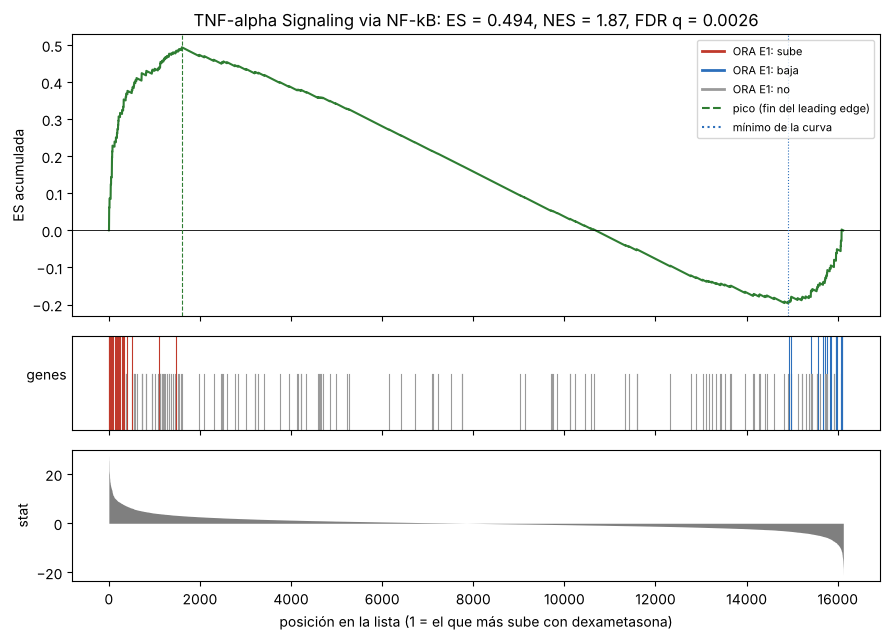

In [15]:
# Figura 1: curva de enriquecimiento de TNF-alpha con los genes coloreados según el ORA de E1
colores_ora = {'sube': '#c0392b', 'baja': '#2c6fbb', 'no': '#9a9a9a'}
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1, 1.4]})
x = np.arange(1, len(curva_tnf) + 1)
a1.plot(x, curva_tnf, color='#2e7d32', lw=1.5)
a1.axhline(0, color='black', lw=0.6)
a1.axvline(int(np.argmax(curva_tnf)) + 1, color='#2e7d32', ls='--', lw=0.8)
a1.axvline(int(np.argmin(curva_tnf)) + 1, color='#2c6fbb', ls=':', lw=0.8)
a1.set_ylabel('ES acumulada')
a1.set_title(f'TNF-alpha Signaling via NF-kB: ES = {gsea.loc[TNF, "ES"]:.3f}, NES = {gsea.loc[TNF, "NES"]:.2f}, '
             f'FDR q = {gsea.loc[TNF, "FDR_q"]:.2g}')
for g in genes_tnf:
    a2.axvline(pos.loc[g, 'posicion'], color=colores_ora[estado_ora[g]], lw=0.8,
               ymax=1 if estado_ora[g] != 'no' else 0.6)
a2.set_yticks([])
a2.set_ylabel('genes', rotation=0, ha='right')
a3.fill_between(x, ranking['stat'], color='#7f7f7f', lw=0)
a3.set_ylabel('stat')
a3.set_xlabel('posición en la lista (1 = el que más sube con dexametasona)')
from matplotlib.lines import Line2D
a1.legend(handles=[Line2D([], [], color=c, lw=2, label=f'ORA E1: {k}') for k, c in colores_ora.items()]
          + [Line2D([], [], color='#2e7d32', ls='--', label='pico (fin del leading edge)'),
             Line2D([], [], color='#2c6fbb', ls=':', label='mínimo de la curva')], fontsize=8, loc='upper right')
plt.tight_layout()
plt.savefig('resultados/E2_figura1_TNF.png', dpi=150)
plt.show()

#### Comparación conjunto a conjunto entre ORA y GSEA

Para los 50 conjuntos junto el resultado del ORA en cada dirección con el de GSEA. Además del NES y su FDR, incluyo el máximo y el mínimo de la curva de enriquecimiento, porque un conjunto con genes en los dos extremos debería tener los dos valores grandes, y cuántos genes del leading edge coinciden con los seleccionados por el ORA en la misma dirección.

In [16]:
filas = []
for c in conjuntos:
    o = ora_res[ora_res['conjunto'] == c].set_index('direccion')
    curva = np.asarray(pre_principal.results[c]['RES'])
    le = set(gsea.loc[c, 'leading_edge'].split(';'))
    dir_gsea = 'sube' if gsea.loc[c, 'NES'] > 0 else 'baja'
    sig_ora = [d for d in ['sube', 'baja'] if o.loc[d, 'q_BH'] < 0.05]
    filas.append({'conjunto': c, 'ORA_k_sube': o.loc['sube', 'k'], 'ORA_q_sube': o.loc['sube', 'q_BH'],
                  'ORA_k_baja': o.loc['baja', 'k'], 'ORA_q_baja': o.loc['baja', 'q_BH'],
                  'ORA_significativo': ' y '.join(sig_ora) if sig_ora else 'ninguna',
                  'NES': gsea.loc[c, 'NES'], 'FDR_q': gsea.loc[c, 'FDR_q'],
                  'curva_max': curva.max(), 'curva_min': curva.min(),
                  'n_leading_edge': len(le), 'LE_seleccionados_ORA_misma_dir': len(le & seleccion[dir_gsea])})
comparacion = pd.DataFrame(filas).sort_values('NES', ascending=False).reset_index(drop=True)
comparacion['GSEA_significativo'] = np.where(comparacion['FDR_q'] < 0.05,
                                             np.where(comparacion['NES'] > 0, 'sube', 'baja'), 'ninguna')
comparacion.to_csv('resultados/E2_comparacion_ORA_GSEA.csv', index=False, float_format='%.17g')
print('Cruce de resultados significativos (filas: ORA E1, columnas: GSEA):')
print(pd.crosstab(comparacion['ORA_significativo'], comparacion['GSEA_significativo']))
vista_c = comparacion.copy()
for c in ['ORA_q_sube', 'ORA_q_baja', 'FDR_q']:
    vista_c[c] = vista_c[c].map(lambda x: f'{x:.2g}')
vista_c.round({'NES': 2, 'curva_max': 2, 'curva_min': 2})

Cruce de resultados significativos (filas: ORA E1, columnas: GSEA):
GSEA_significativo  ninguna  sube
ORA_significativo                
baja                      6     0
ninguna                  26     5
sube                      1     6
sube y baja               5     1


,conjunto,ORA_k_sube,ORA_q_sube,ORA_k_baja,ORA_q_baja,ORA_significativo,NES,FDR_q,curva_max,curva_min,n_leading_edge,LE_seleccionados_ORA_misma_dir,GSEA_significativo
0,Adipogenesis,13,0.019,1,1,sube,1.91,0.001,0.50,-0.07,57,13,sube
1,TNF-alpha Signaling via NF-kB,26,1.6e-09,15,0.0017,sube y baja,1.87,0.0026,0.49,-0.20,60,26,sube
2,Androgen Response,7,0.063,4,0.46,ninguna,1.77,0.0031,0.51,-0.17,33,7,sube
3,Xenobiotic Metabolism,13,0.0066,6,0.46,sube,1.63,0.019,0.44,-0.14,57,13,sube
4,Reactive Oxygen Species Pathway,4,0.13,1,0.95,ninguna,1.63,0.015,0.54,-0.12,10,4,sube
5,UV Response Dn,11,0.017,7,0.24,sube,1.63,0.014,0.44,-0.22,40,11,sube
6,Fatty Acid Metabolism,6,0.43,1,1,ninguna,1.62,0.014,0.44,-0.05,37,6,sube
7,IL-2/STAT5 Signaling,13,0.0073,4,0.88,sube,1.58,0.018,0.43,-0.17,44,13,sube
8,Complement,6,0.46,2,1,ninguna,1.55,0.025,0.42,-0.09,44,6,sube
9,Oxidative Phosphorylation,4,0.98,0,1,ninguna,1.54,0.023,0.41,-0.02,68,4,sube


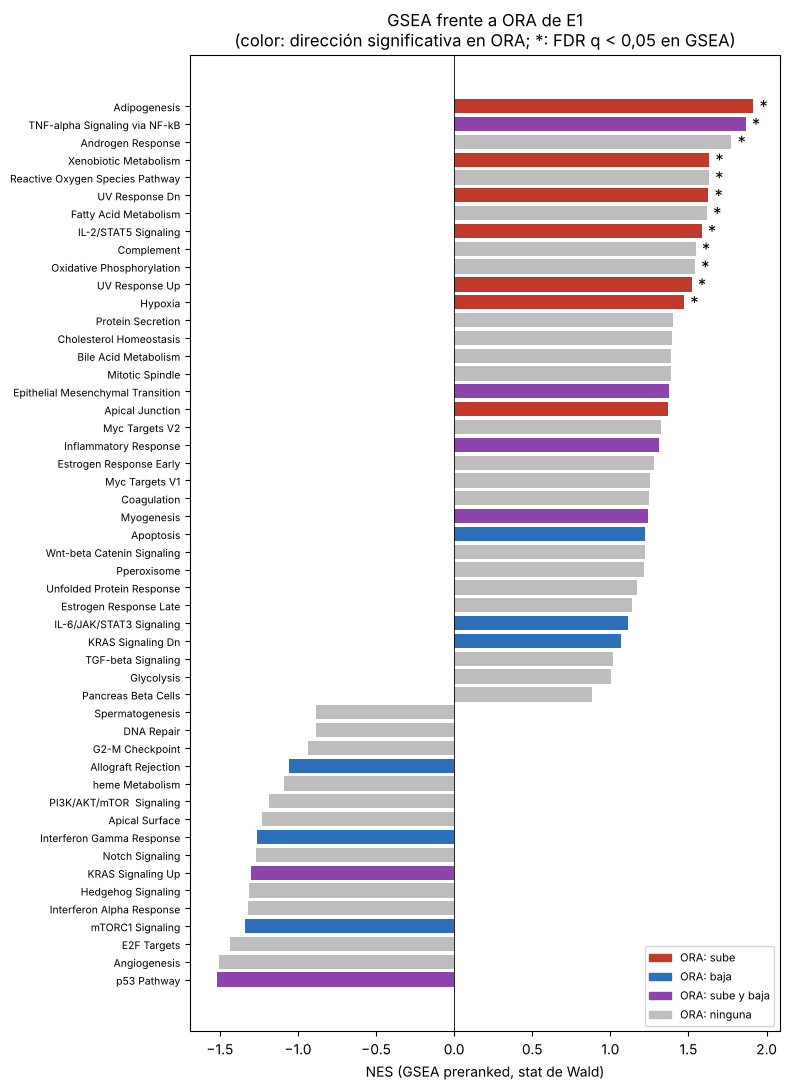

In [17]:
# Figura 2: NES de los 50 conjuntos, coloreados según lo que dio el ORA de E1
paleta = {'sube': '#c0392b', 'baja': '#2c6fbb', 'sube y baja': '#8e44ad', 'ninguna': '#bdbdbd'}
d = comparacion.sort_values('NES')
fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(d['conjunto'], d['NES'], color=d['ORA_significativo'].map(paleta))
for i, (_, f) in enumerate(d.iterrows()):
    if f['FDR_q'] < 0.05:
        ax.text(f['NES'] + (0.04 if f['NES'] > 0 else -0.04), i, '*', va='center',
                ha='left' if f['NES'] > 0 else 'right', fontsize=12)
ax.axvline(0, color='black', lw=0.6)
ax.set_xlabel('NES (GSEA preranked, stat de Wald)')
ax.set_title('GSEA frente a ORA de E1\n(color: dirección significativa en ORA; *: FDR q < 0,05 en GSEA)')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=f'ORA: {k}') for k, c in paleta.items()],
          fontsize=8, loc='lower right')
ax.tick_params(axis='y', labelsize=7.5)
plt.tight_layout()
plt.savefig('resultados/E2_figura2_NES_vs_ORA.png', dpi=150)
plt.show()

## E2-verificacion

Realiza dos comprobaciones acotadas: una sobre una decisión analítica y otra numérica o de implementación. Cambia una cosa cada vez. Para cada prueba identifica referencia, cambio, elementos fijos, resultado observado y consecuencia para la conclusión. Distingue sensibilidad entre alternativas válidas de un error que debes corregir. No basta comparar el número de términos significativos.

Añade aquí tu explicación y las celdas necesarias.


Hago dos comprobaciones, cambiando una sola cosa en cada una. La primera es analítica (cambio el estadístico con el que se ordena la lista) y mide la sensibilidad de la conclusión ante otra decisión razonable. La segunda es de implementación (vuelvo a calcular la ES, el leading edge y la distribución nula con código propio) y sirve para detectar errores en cómo he usado gseapy. Son preguntas distintas: un cambio en la primera no sería un error, sino una dependencia de la decisión; una discrepancia en la segunda sí sería un error que habría que corregir.

#### Comprobación A (decisión analítica): ordenar por `log2FoldChange` en lugar de por `stat`

La referencia es el GSEA principal, con la lista ordenada por `stat`. El cambio consiste en ordenar los mismos 16.122 genes por `log2FoldChange` (desempatando también por símbolo). Se mantienen fijos el universo, la regla de duplicados, la colección, `weight`, los tamaños, el número de permutaciones y la semilla. Es una alternativa que se usa a menudo y que es razonable, aunque tiene el problema ya comentado de que este log2FC no está contraído.

In [18]:
# Comprobación A: se cambia SOLO el estadístico del ranking (stat -> log2FoldChange).
# Fijos: universo, regla de duplicados, colección, weight, tamaños, permutaciones y semilla.
ranking_lfc = ranking.sort_values(['log2FoldChange', 'symbol'], ascending=[False, True]).reset_index(drop=True)
ranking_lfc['posicion'] = np.arange(1, len(ranking_lfc) + 1)
gsea_lfc, pre_lfc = ejecutar_gsea(ranking_lfc, 'log2FoldChange')

comp_A = gsea[['NES', 'FDR_q', 'n_leading_edge']].join(gsea_lfc[['NES', 'FDR_q', 'n_leading_edge']], rsuffix='_lfc')
comp_A['jaccard_LE'] = [len(set(gsea.loc[c, 'leading_edge'].split(';')) & set(gsea_lfc.loc[c, 'leading_edge'].split(';')))
                        / len(set(gsea.loc[c, 'leading_edge'].split(';')) | set(gsea_lfc.loc[c, 'leading_edge'].split(';')))
                        for c in comp_A.index]
comp_A['mismo_signo'] = np.sign(comp_A['NES']) == np.sign(comp_A['NES_lfc'])
comp_A.reset_index().to_csv('resultados/E2_verificacion_A_log2FC.csv', index=False, float_format='%.17g')

print('Correlación de Spearman entre los NES de los 50 conjuntos:', round(stats.spearmanr(comp_A['NES'], comp_A['NES_lfc'])[0], 3))
print('Conjuntos que cambian de signo:', (~comp_A['mismo_signo']).sum())
print(comp_A.loc[~comp_A['mismo_signo'], ['NES', 'FDR_q', 'NES_lfc', 'FDR_q_lfc']].to_string(float_format=lambda x: f'{x:.3g}'))
sig_stat, sig_lfc = set(comp_A.index[comp_A['FDR_q'] < 0.05]), set(comp_A.index[comp_A['FDR_q_lfc'] < 0.05])
print('FDR < 0.05 con stat:', len(sig_stat), '| con log2FC:', len(sig_lfc), '| en ambos:', len(sig_stat & sig_lfc))
print('Dejan de ser significativos con log2FC:', ', '.join(sorted(sig_stat - sig_lfc)))
print('Aparecen solo con log2FC:', ', '.join(sorted(sig_lfc - sig_stat)) or 'ninguno')
print()
interes = [TNF, 'Androgen Response', 'Reactive Oxygen Species Pathway', 'Fatty Acid Metabolism', 'Complement',
           'Oxidative Phosphorylation', 'Inflammatory Response', 'Epithelial Mesenchymal Transition', 'p53 Pathway', 'KRAS Signaling Up',
           'Myogenesis', 'Interferon Gamma Response', 'IL-6/JAK/STAT3 Signaling', 'Allograft Rejection']
print(comp_A.loc[interes].to_string(float_format=lambda x: f'{x:.3g}'))

2026-11-07 19:26:29,739 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Correlación de Spearman entre los NES de los 50 conjuntos: 0.82
Conjuntos que cambian de signo: 6
                           NES  FDR_q  NES_lfc  FDR_q_lfc
conjunto                                                 
Inflammatory Response     1.31  0.114    -1.14      0.349
Estrogen Response Early   1.28  0.138    -1.29      0.476
Myogenesis                1.24  0.158    -1.14      0.372
IL-6/JAK/STAT3 Signaling  1.11  0.293    -1.15      0.399
Pancreas Beta Cells       0.88  0.712    -0.91      0.735
p53 Pathway              -1.52  0.169     1.29      0.137
FDR < 0.05 con stat: 12 | con log2FC: 2 | en ambos: 2
Dejan de ser significativos con log2FC: Complement, Fatty Acid Metabolism, Hypoxia, IL-2/STAT5 Signaling, Oxidative Phosphorylation, Reactive Oxygen Species Pathway, TNF-alpha Signaling via NF-kB, UV Response Dn, UV Response Up, Xenobiotic Metabolism
Aparecen solo con log2FC: ninguno

                                    NES   FDR_q  n_leading_edge  NES_lfc  FDR_q_lfc  n_leading_edg

In [19]:
# ¿Por qué cambia? Qué genes ocupan el principio de cada lista y qué pasa con el leading edge de TNF-alpha
print('Primeros 10 genes ordenando por stat y por log2FC (con su baseMean):')
print(pd.concat([ranking.head(10)[['symbol', 'stat', 'log2FoldChange', 'baseMean']].reset_index(drop=True),
                 ranking_lfc.head(10)[['symbol', 'stat', 'log2FoldChange', 'baseMean']].reset_index(drop=True)],
                axis=1, keys=['orden por stat', 'orden por log2FC']).to_string(float_format=lambda x: f'{x:.3g}'))
for nombre, tab in [('stat', ranking), ('log2FC', ranking_lfc)]:
    print(f'Mediana de baseMean de los 200 primeros y 200 últimos genes ordenando por {nombre}:',
          round(pd.concat([tab.head(200), tab.tail(200)])['baseMean'].median(), 1))
le_lfc = gsea_lfc.loc[TNF, 'leading_edge'].split(';')
pos_lfc = ranking_lfc.set_index('symbol')
print(f'\nTNF-alpha con log2FC: leading edge de {len(le_lfc)} genes; comparte {len(set(le_lfc) & set(le_tnf))} con el de stat.')
print('Solo en el de log2FC:', ', '.join(g for g in le_lfc if g not in le_tnf))
print('Solo en el de stat:', ', '.join(g for g in le_tnf if g not in le_lfc))
print('Posición de DUSP1, PER1 y KLF9 con stat / con log2FC:',
      {g: (int(pos.loc[g, 'posicion']), int(pos_lfc.loc[g, 'posicion'])) for g in ['DUSP1', 'PER1', 'KLF9']})

Primeros 10 genes ordenando por stat y por log2FC (con su baseMean):
  orden por stat                              orden por log2FC                             
          symbol stat log2FoldChange baseMean           symbol stat log2FoldChange baseMean
0        SPARCL1 27.5           4.57      998          ALOX15B 5.72            9.5     67.3
1         SAMHD1 27.2           3.76 1.27e+04           ZBTB16 13.7           7.35      385
2           MAOA 25.6           3.35 2.34e+03    RP11-357D18.1  9.6           6.31     56.3
3           GPX3 25.5           3.73 1.23e+04           STEAP4 10.5            5.2      287
4          DUSP1 25.3           2.94 3.41e+03          ANGPTL7 6.63           5.08      255
5         CACNB2 23.7           3.29      496            PRODH   10           4.89     55.4
6          KLF15 21.6           4.46      561          FAM107A 15.6           4.81      160
7           PER1 21.1           3.19      777             LGI3 6.23           4.75       21
8        AD

#### Resultado y consecuencia de la comprobación A

TNF-alpha conserva el signo y casi todo el leading edge: el NES pasa de 1,87 a 1,55 y, de los 62 genes del nuevo leading edge, 54 estaban en el original (índice de Jaccard 0,79). DUSP1, PER1 y KLF9 siguen cerca del principio de la lista, aunque bajan de posición (DUSP1 de la 5 a la 39). Lo que cambia es la significación: la FDR q pasa de 0,0026 a 0,069 y deja de cumplir el corte de 0,05.

El efecto es general, no solo de TNF-alpha. Con `log2FoldChange` solo quedan 2 conjuntos con FDR q < 0,05 (Adipogenesis y Androgen Response) frente a 12 con `stat`, aunque la correlación de Spearman entre los NES de los 50 conjuntos sigue siendo 0,82. La razón se ve en la segunda celda: al ordenar por log2FC, los extremos de la lista los ocupan genes con pocos recuentos (la mediana de `baseMean` de los 200 primeros y los 200 últimos es de unos 100, frente a unos 1.019 con `stat`), como ALOX15B o LGI3, cuyos cambios grandes son poco precisos. Esos genes no están en los conjuntos y diluyen la señal de los demás. Seis conjuntos cambian de signo (Inflammatory Response, Estrogen Response Early, Myogenesis, IL-6/JAK/STAT3, Pancreas Beta Cells y p53 Pathway), todos con FDR q mayor de 0,1 en las dos versiones, lo que indica que su dirección no es estable.

Esto no es un error que haya que corregir, sino una sensibilidad entre dos alternativas, de las que considero mejor justificada `stat` por el motivo dado en el método. La consecuencia para la conclusión es que la dirección y los genes del resultado de TNF-alpha son robustos al estadístico, pero su significación a 0,05 no lo es del todo. Por eso, en la síntesis, la afirmación sobre la dirección la mantengo con más seguridad que la de que el resultado sea muy significativo.

#### Comprobación B (implementación): rehacer la ES, el leading edge y el modelo nulo sin gseapy

La referencia es la salida de gseapy. El cambio es el código que calcula: programo la suma acumulada del paso 2 de Subramanian et al. (2005), en la que cada gen del conjunto suma |stat|^p / NR (con NR la suma de |stat|^p de los genes del conjunto, y p = 1) y cada gen de fuera resta 1/(N - Nh). La ES es la máxima desviación respecto a cero y el leading edge son los genes del conjunto anteriores al pico (o posteriores, si la ES es negativa). Se mantienen fijos la lista ordenada por `stat` y los conjuntos. Esta prueba detectaría que gseapy hubiera reordenado la lista, que hubiera emparejado mal los símbolos o que yo hubiera interpretado mal sus columnas. Para TNF-alpha construyo además un nulo propio con 2.000 conjuntos aleatorios del mismo tamaño, que es lo mismo que hace gseapy al permutar genes, y recalculo la p y el NES con las definiciones de GSEA (la p con la parte de la distribución nula del mismo signo que la ES, y el NES dividiendo por la media de esa parte).

In [20]:
# Comprobación B: implementación propia de la ES (Subramanian et al., 2005, paso 2) sin usar gseapy.
# Fijos: la misma lista ordenada por stat y los mismos conjuntos. Lo único que cambia es el código que calcula.
genes_lista = ranking['symbol'].to_numpy()
valores = ranking['stat'].to_numpy()

def curva_es(en_conjunto, valores, p=1.0):
    # Suma acumulada: sube |r|^p / NR en cada gen del conjunto y baja 1/(N - Nh) en los demás
    w = np.abs(valores) ** p
    paso = np.where(en_conjunto, w / w[en_conjunto].sum(), -1.0 / (len(valores) - en_conjunto.sum()))
    return np.cumsum(paso)

def es_y_le(conjunto):
    en = np.isin(genes_lista, list(conjuntos[conjunto]))
    curva = curva_es(en, valores, PARAMETROS['weight'])
    i = int(np.argmax(np.abs(curva)))      # máxima desviación respecto a cero
    es = curva[i]
    le = list(genes_lista[:i + 1][en[:i + 1]]) if es > 0 else list(genes_lista[i:][en[i:]])
    return es, le

difs, le_iguales = [], 0
for c in conjuntos:
    es_propia, le_propio = es_y_le(c)
    difs.append(abs(es_propia - gsea.loc[c, 'ES']))
    le_iguales += set(le_propio) == set(gsea.loc[c, 'leading_edge'].split(';'))
print(f'Diferencia máxima entre la ES propia y la de gseapy en los 50 conjuntos: {max(difs):.2e}')
print(f'Conjuntos con el mismo leading edge en las dos implementaciones: {le_iguales} de {len(conjuntos)}')
es_tnf, le_propio_tnf = es_y_le(TNF)
print(f'TNF-alpha: ES propia = {es_tnf:.6f} | gseapy = {gsea.loc[TNF, "ES"]:.6f} | leading edge propio de {len(le_propio_tnf)} genes')
assert max(difs) < 1e-6 and le_iguales == len(conjuntos)

Diferencia máxima entre la ES propia y la de gseapy en los 50 conjuntos: 1.05e-13
Conjuntos con el mismo leading edge en las dos implementaciones: 50 de 50
TNF-alpha: ES propia = 0.493898 | gseapy = 0.493898 | leading edge propio de 60 genes


In [21]:
# Modelo nulo propio para TNF-alpha: conjuntos aleatorios del mismo tamaño sacados de la misma lista
# (equivale a permutar genes; NO a permutar muestras). Semilla y número de permutaciones propios.
rng = np.random.default_rng(PARAMETROS['semilla'])
n_conj = int(np.isin(genes_lista, list(conjuntos[TNF])).sum())
n_perm_propio = 2000
nulas = np.empty(n_perm_propio)
for b in range(n_perm_propio):
    en = np.zeros(len(genes_lista), dtype=bool)
    en[rng.choice(len(genes_lista), n_conj, replace=False)] = True
    curva = curva_es(en, valores, PARAMETROS['weight'])
    nulas[b] = curva[np.argmax(np.abs(curva))]
# Como en GSEA, la p nominal se calcula con la parte de la distribución nula del mismo signo que la ES
n_pos = int((nulas >= 0).sum())
n_superan = int((nulas >= es_tnf).sum())
nes_propio = es_tnf / nulas[nulas >= 0].mean()
print(f'Nulo propio ({n_perm_propio} conjuntos aleatorios de {n_conj} genes): ES nula máxima = {nulas.max():.3f}, '
      f'percentil 99 = {np.percentile(nulas, 99):.3f}')
print(f'ES nulas positivas: {n_pos}; de ellas igualan o superan la ES observada: {n_superan} '
      f'-> p propia {"< " + format(1 / n_pos, ".2g") if n_superan == 0 else format(n_superan / n_pos, ".2g")} | gseapy: {gsea.loc[TNF, "p_nominal_texto"]}')
print(f'NES propio = ES / media de las ES nulas positivas = {nes_propio:.3f} | NES de gseapy = {gsea.loc[TNF, "NES"]:.3f}')

Nulo propio (2000 conjuntos aleatorios de 172 genes): ES nula máxima = 0.429, percentil 99 = 0.372
ES nulas positivas: 1402; de ellas igualan o superan la ES observada: 0 -> p propia < 0.00071 | gseapy: < 0.001
NES propio = ES / media de las ES nulas positivas = 1.859 | NES de gseapy = 1.866


#### Resultado y consecuencia de la comprobación B

La ES calculada con mi código coincide con la de gseapy en los 50 conjuntos (la diferencia máxima es del orden de 1e-13, es decir, error de redondeo) y el leading edge es idéntico en los 50. Para TNF-alpha, ninguna de las ES nulas propias llega a la observada, de modo que la p queda por debajo de la resolución de las permutaciones, igual que en gseapy, y el NES propio (1,86) es prácticamente el de gseapy (1,87); la pequeña diferencia es la esperable con otras permutaciones. La ES nula más alta de las 2.000 fue 0,43, por debajo de la ES observada de 0,494.

No hay, por tanto, ningún error de implementación que corregir, y la tabla, el leading edge y la figura se pueden usar tal cual. El límite de esta prueba es que repite el mismo modelo nulo de permutación de genes, así que no resuelve su problema de fondo: ninguna de las dos implementaciones tiene en cuenta las correlaciones entre genes, y la p de TNF-alpha seguramente es más pequeña de lo que daría una permutación de muestras.

## E2-interpretacion

Compara ORA y lista ordenada con resultados y genes concretos. Explica acuerdos y discrepancias sin exigir igualdad de listas. Presenta una conclusión robusta o su ausencia, qué mantienes o revisas respecto a E1 y los límites restantes. No es obligatorio cambiar de opinión. Redes solo si responden una necesidad justificada; son opcionales.

Añade aquí tu explicación y las celdas necesarias.


Antes de redactar las conclusiones miro dos cosas que afectan a cómo se lee el resultado de TNF-alpha: si sus genes del leading edge son los mismos que sostienen otros conjuntos significativos en GSEA (redundancia) y qué ocurre con los otros cinco conjuntos que en E1 salieron en las dos direcciones.

In [22]:
# Redundancia entre leading edges de los conjuntos significativos en GSEA
sig_g = gsea[gsea['FDR_q'] < 0.05]
le_sets = {c: set(sig_g.loc[c, 'leading_edge'].split(';')) for c in sig_g.index}
print('Conjuntos con FDR q < 0.05:', len(sig_g))
solap = pd.DataFrame([{'conjunto': c, 'n_LE': len(le_sets[c]), 'comparte_con_TNF': len(le_sets[c] & le_sets[TNF]),
                       'genes_compartidos': ', '.join(g for g in le_tnf if g in le_sets[c])}
                      for c in sig_g.index if c != TNF]).sort_values('comparte_con_TNF', ascending=False)
print(solap.to_string(index=False))
cuenta = pd.Series([g for s in le_sets.values() for g in s]).value_counts()
print('\nGenes en el leading edge de 4 o más conjuntos significativos:')
print(', '.join(f'{g} ({v})' for g, v in cuenta[cuenta >= 4].items()))

Conjuntos con FDR q < 0.05: 12
                       conjunto  n_LE  comparte_con_TNF                                                                     genes_compartidos
                        Hypoxia    38                13 DUSP1, IRS2, ATF3, MAFF, KLF6, NFIL3, TIPARP, F3, TNFAIP3, PFKFB3, PNRC1, BTG1, ZFP36
           IL-2/STAT5 Signaling    44                 8                                   MAFF, GADD45B, KLF6, RHOB, MAP3K8, NFIL3, MYC, CSF1
                 UV Response Up    29                 7                                           ATF3, RHOB, GCH1, NR4A1, NFKBIA, SOD2, BTG1
                     Complement    44                 6                                                 MAFF, DUSP5, F3, TNFAIP3, EHD1, CEBPB
                 UV Response Dn    40                 6                                                  DUSP1, PDLIM5, MYC, F3, LDLR, ATP2B1
              Androgen Response    33                 6                                          PDLIM5, TSC22D1, SAT

In [23]:
# Los seis conjuntos que el ORA de E1 dio en las dos direcciones
ambas = comparacion[comparacion['ORA_significativo'] == 'sube y baja']
print(ambas[['conjunto', 'ORA_k_sube', 'ORA_k_baja', 'NES', 'FDR_q', 'curva_max', 'curva_min', 'n_leading_edge',
             'LE_seleccionados_ORA_misma_dir']].to_string(index=False, float_format=lambda x: f'{x:.3g}'))
print('\nConjuntos de la conclusión 2 de E1 (bajan en ORA):')
print(comparacion[comparacion['conjunto'].isin(['Interferon Gamma Response', 'IL-6/JAK/STAT3 Signaling', 'Allograft Rejection'])]
      [['conjunto', 'ORA_k_sube', 'ORA_k_baja', 'NES', 'FDR_q', 'curva_max', 'curva_min']].to_string(index=False, float_format=lambda x: f'{x:.3g}'))

                         conjunto  ORA_k_sube  ORA_k_baja   NES   FDR_q  curva_max  curva_min  n_leading_edge  LE_seleccionados_ORA_misma_dir
    TNF-alpha Signaling via NF-kB          26          15  1.87 0.00258      0.494     -0.197              60                              26
Epithelial Mesenchymal Transition          18          18  1.37  0.0775      0.355     -0.348              49                              18
            Inflammatory Response          10          13  1.31   0.114      0.361     -0.236              34                              10
                       Myogenesis          12          11  1.24   0.158      0.333      -0.31              35                              12
                KRAS Signaling Up          13          14  -1.3    0.14      0.284     -0.323              35                              14
                      p53 Pathway          13          21 -1.52   0.169      0.244     -0.368              47                              21

Conju

In [24]:
# Genes de respuesta a glucocorticoides citados por Himes et al. (2014): posición en la lista y conjuntos
for g in ['DUSP1', 'PER1', 'KLF15', 'TSC22D3', 'CRISPLD2']:
    en_c = [k for k, v in conjuntos.items() if g in v]
    print(f'{g}: posición {int(pos.loc[g, "posicion"])} de {len(pos)} | stat = {pos.loc[g, "stat"]:.1f} | '
          f'conjuntos: {", ".join(en_c) if en_c else "(ninguno)"}')

DUSP1: posición 5 de 16122 | stat = 25.3 | conjuntos: TNF-alpha Signaling via NF-kB, Hypoxia, UV Response Dn
PER1: posición 8 de 16122 | stat = 21.1 | conjuntos: TNF-alpha Signaling via NF-kB
KLF15: posición 7 de 16122 | stat = 21.6 | conjuntos: (ninguno)
TSC22D3: posición 174 de 16122 | stat = 9.4 | conjuntos: (ninguno)
CRISPLD2: posición 26 de 16122 | stat = 16.8 | conjuntos: (ninguno)


### Conclusiones

Como en E1, separo lo que se observa en las salidas, cómo lo interpreto y qué hipótesis o duda queda.

#### 1. TNF-alpha: la señal no es débil ni repartida, está dominada por los genes que suben (la conclusión que contrasto)

*Observación.* En GSEA, TNF-alpha Signaling via NF-kB tiene NES = 1,87, p nominal < 0,001 y FDR q = 0,0026, el segundo NES más alto de los 50 conjuntos. Su leading edge son 60 de sus 172 genes, todos dentro del primer 10 % de la lista (pico en la posición 1.603). Contiene los 26 genes que el ORA de E1 seleccionaba como "sube" (DUSP1 en la posición 5, PER1 en la 8, PTX3, IRS2, KLF9, CEBPD, ATF3, NR4A3...) y otros 34 que el ORA no veía porque cambian menos del doble, como NFKBIA (log2FC = 0,79), TNFAIP3 (0,56), TNIP1, TNIP2, MCL1 o ZFP36. El otro extremo también existe: la curva baja hasta -0,197 en la posición 14.907 y en esa cola inferior hay 35 genes del conjunto, entre ellos los 15 que el ORA seleccionaba como "baja" (LIF, CDKN1A, G0S2, TNFAIP6, EGR2, PTGS2, VEGFA, JUN...). En total, del conjunto hay 62 genes con padj < 0,05 que suben y 39 que bajan.

*Interpretación.* La hipótesis H1 de E1 no se cumple para este conjunto, y la que encaja con los datos es H2. Que haya genes en los dos extremos no basta para que la señal sea débil: depende del equilibrio. Aquí la parte que sube es más numerosa y está más concentrada al principio de la lista, y la desviación negativa (-0,197) es menos de la mitad de la positiva (0,494). GSEA resume el conjunto con la desviación mayor, así que el NES positivo no significa que no haya genes que bajen ni que todo el conjunto suba: el leading edge son 60 de 172 genes, la cola inferior 35, y los 77 restantes quedan en la zona central de la lista. Por eso ha hecho falta mirar la curva entera y la cola inferior. La lectura de E1 sale reforzada en cuanto a los genes. En el leading edge, además de DUSP1 y PER1, que Himes et al. (2014) citan como respuesta conocida a glucocorticoides, aparecen NFKBIA y TNFAIP3, que se describen habitualmente como inhibidores de la propia vía NF-kB, mientras que lo que baja son sobre todo mediadores secretados o genes de respuesta temprana (LIF, TNFAIP6, PTGS2, VEGFA).

*Hipótesis.* Mantengo como hipótesis, y no como resultado, que la dexametasona induce en estas células un grupo de reguladores negativos de la señal NF-kB a la vez que reprime algunos de sus productos. Los datos son de ARN y no miden la actividad de la vía, así que comprobarlo exigiría otro tipo de experimento (por ejemplo, medir la proteína IκBα o la actividad de NF-kB en células estimuladas con TNF, con y sin dexametasona).

*Robustez.* La implementación está verificada (comprobación B). La dirección del resultado y su leading edge se mantienen al ordenar por log2FC (comprobación A), pero la FDR sube a 0,069. Además, el leading edge de TNF-alpha comparte 13 genes con el de Hypoxia (DUSP1, IRS2, ATF3, MAFF, KLF6, NFIL3, ZFP36...), 8 con el de IL-2/STAT5 y 7 con el de UV Response Up, de modo que esos resultados positivos de GSEA no son independientes del de TNF-alpha, igual que pasaba con la redundancia en E1.

#### 2. Los conjuntos inmunitarios que "bajaban" en el ORA no aparecen como desplazamiento del conjunto completo

*Observación.* Ninguno de los 6 conjuntos que el ORA de E1 daba significativos solo en "baja" es significativo en GSEA, y no hay ningún conjunto con NES negativo y FDR q < 0,05. Interferon Gamma Response tiene NES = -1,26 (FDR 0,15) y Allograft Rejection -1,05 (FDR 0,41), mientras que IL-6/JAK/STAT3 Signaling tiene NES positivo (1,11; FDR 0,29). Inflammatory Response, que el ORA daba en las dos direcciones, tiene NES = 1,31 (FDR 0,11).

*Interpretación.* Que estos conjuntos no sean significativos en GSEA no demuestra que no haya represión: una FDR alta indica falta de evidencia de un desplazamiento del conjunto, no ausencia de efecto. Las dos cosas son compatibles. El ORA detecta que unos pocos genes del conjunto cambian mucho (en E1, por ejemplo CCL7, LIF, TNFAIP6 o TNFSF15), y eso sigue siendo cierto porque son los mismos datos. GSEA, en cambio, pregunta si el conjunto en su conjunto se acumula en un extremo de la lista, y aquí los demás genes de estos programas están repartidos o se compensan con otros que suben, como se ve en que la curva tiene máximo y mínimo de tamaño parecido (en Interferon Gamma Response, 0,256 y -0,302). Por eso no retiro la conclusión 2 de E1, sino que la matizo: los datos apoyan la bajada de un grupo concreto de mediadores, pero no permiten afirmar que la dexametasona reprima esos programas inmunitarios completos. Como en E1 ya decía que no eran pruebas independientes, esto la acota más que contradecirla.

#### 3. Los otros conjuntos bidireccionales sí dan una señal débil

*Observación.* De los 6 conjuntos que el ORA de E1 daba en las dos direcciones, 5 no son significativos en GSEA: EMT (NES = 1,37; FDR 0,078), Inflammatory Response (1,31; 0,11), Myogenesis (1,24; 0,16), KRAS Signaling Up (-1,30; 0,14) y p53 Pathway (-1,52; 0,17). En ellos el máximo y el mínimo de la curva tienen tamaños parecidos (en EMT, 0,355 y -0,348), a diferencia de TNF-alpha (0,494 y -0,197). Además, tres de ellos cambian de signo al ordenar por log2FC (Inflammatory Response, Myogenesis y p53 Pathway).

*Interpretación.* Para estos cinco conjuntos la predicción de E1 se cumple, y no solo porque la FDR sea alta: la propia curva muestra una señal repartida, con desviaciones parecidas hacia los dos extremos. Para TNF-alpha no se cumple. Lo que separa unos casos de otros no es que el conjunto tenga genes en las dos direcciones, sino si una de ellas domina. Mantengo lo que decía E1 de que no se puede afirmar que el tratamiento "reprima la EMT" o "inhiba p53".

#### 4. Lo que GSEA encuentra y el ORA no

*Observación.* Cinco conjuntos son significativos en GSEA sin haberlo sido en ninguna dirección del ORA: Androgen Response, Reactive Oxygen Species Pathway, Fatty Acid Metabolism, Complement y Oxidative Phosphorylation, todos con NES positivo. En Oxidative Phosphorylation, por ejemplo, el leading edge tiene 68 genes y solo 4 de ellos estaban seleccionados en el ORA.

*Hipótesis.* Son conjuntos donde muchos genes suben un poco sin llegar al corte de |log2FC| >= 1, justo el tipo de señal que solo ve un método con lista ordenada (Khatri et al., 2012). Queda como pregunta nueva si reflejan un efecto metabólico del glucocorticoide o genes compartidos entre conjuntos, algo que habría que estudiar revisando sus leading edges como se ha hecho con TNF-alpha. No lo interpreto más porque no es la conclusión que contrasto y porque son menos estables que TNF-alpha: con `log2FoldChange` solo Androgen Response sigue por debajo de 0,05 (los otros cuatro quedan entre 0,06 y 0,1) y, con 1.000 permutaciones, varios están cerca del umbral.

### Síntesis: qué mantengo, matizo o retiro respecto a E1

Mantengo la conclusión contrastada en su forma central. TNF-alpha via NF-kB es un resultado fuerte y orientado hacia los genes que suben con dexametasona, sostenido por genes de respuesta a glucocorticoides y reguladores (DUSP1, PER1, KLF9, NFKBIA, TNFAIP3), mientras que un grupo menor de mediadores del mismo conjunto baja (LIF, TNFAIP6, PTGS2, CDKN1A). Esta conclusión resiste el cambio de método (de ORA a GSEA), el cambio de estadístico en cuanto a dirección y genes, y la reimplementación.

Matizo su fuerza, porque la significación a 0,05 depende del estadístico (FDR 0,0026 con `stat` y 0,069 con log2FC) y porque la p procede de un nulo que permuta genes. Retiro la predicción de E1 de que GSEA daría una señal débil para TNF-alpha: era una hipótesis razonable y no se ha cumplido. Matizo la conclusión 2 de E1: la bajada de mediadores concretos se mantiene, pero GSEA no da evidencia de que se repriman los programas inmunitarios completos, lo que no equivale a demostrar que no se repriman. Y mantengo la conclusión 3 de E1 para los otros cinco conjuntos bidireccionales.

### Incertidumbre y límites que permanecen

- El modelo nulo permuta genes y no muestras. No conserva las correlaciones entre genes, por lo que las p y las FDR son probablemente optimistas. Con 4 pares de células no es posible una permutación de muestras útil.
- Con 1.000 permutaciones la precisión de la p es limitada (0,001 como mínimo). Al repetir con la semilla 123 (sección de reproducibilidad) salen los mismos 12 conjuntos significativos y TNF-alpha apenas cambia (NES 1,84, FDR 0,0041, mismo leading edge), pero las FDR se mueven hasta 0,04, así que un conjunto cercano a 0,05 podría cambiar de lado con otra semilla.
- Los símbolos renombrados siguen sin cruzarse. CYR61 (que en el GMT se llama CCN1 y está en TNF-alpha) sube claramente (stat = 5,7), así que su ausencia probablemente resta algo de señal a TNF-alpha y no la crea.
- Hallmark no cubre una parte importante de la respuesta: KLF15 (posición 7), CRISPLD2 (posición 26) y TSC22D3 (posición 174), tres genes destacados por Himes et al. (2014), no están en ningún conjunto.
- Dentro del universo, los genes más expresados tienen más facilidad para obtener un `stat` grande (Young et al., 2010), y ese sesgo tampoco se corrige al ordenar por `stat`.
- Todo son cambios de ARN en células en cultivo de 4 donantes: no demuestran actividad de una vía ni dicen nada de un efecto clínico. No he usado propagación en redes porque la pregunta se responde volviendo a los genes del leading edge y no hacía falta ampliar la lista con vecinos de una red.

## E2-reproducibilidad

Trabaja esta sección durante todas las sesiones y ciérrala en Declara dependencias y versiones realmente usadas, parámetros, semillas, fecha de ejecución, rutas y limitaciones. Incluye las instrucciones de instalación que tu análisis necesite antes de sus imports. Conserva el código necesario para reconstruir los resultados desde el paquete común.

Reinicia el entorno y ejecuta en orden; documenta cualquier fallo sin afirmar una ejecución que no hiciste. Guarda las salidas. Declara los archivos auxiliares necesarios y por qué. Si exportas números, conserva precisión: no conviertas p pequeños en ceros mediante redondeo. La última celda genera y descarga juntos el cuaderno final y su índice JSON.


In [25]:
import importlib.metadata as md_
print('Fecha de ejecución:', datetime.datetime.now().astimezone().isoformat(timespec='seconds'))
print('Sistema:', platform.platform(), '| Python', sys.version.split()[0])
print('Ejecutado en Google Colab:', 'google.colab' in sys.modules)
for paquete in ['pandas', 'numpy', 'scipy', 'statsmodels', 'matplotlib', 'gseapy']:
    print(f'  {paquete}=={md_.version(paquete)}')
print('Paquete de datos:', procedencia['package_id'], '| ZIP:', ZIP)
print('SHA256 del manifiesto:', hashlib.sha256(Path('MANIFEST_SHA256.json').read_bytes()).hexdigest())
print('SHA256 de la colección (procedencia):', procedencia['collection_sha256'])
print('Parámetros:')
for k, v in PARAMETROS.items():
    print(f'  {k}: {v}')
print('Semillas: gseapy seed =', PARAMETROS['semilla'], '(análisis principal y comprobación A);',
      'numpy default_rng(', PARAMETROS['semilla'], ') para el nulo propio de la comprobación B')
print('Archivos generados:')
for f in sorted(Path('resultados').glob('E2_*')):
    print(f'  {f}  {f.stat().st_size} bytes  sha256={hashlib.sha256(f.read_bytes()).hexdigest()[:16]}...')

Fecha de ejecución: 2026-11-07T19:26:34+00:00
Sistema: Linux-6.18.44-fc-v310-x86_64-with-glibc2.39 | Python 3.13.18
Ejecutado en Google Colab: False
  pandas==2.2.3
  numpy==2.1.3
  scipy==1.18.1
  statsmodels==0.15.0
  matplotlib==3.11.2
  gseapy==1.3.2
Paquete de datos: hab-airway-26-27-v1.1 | ZIP: airway_26-27_v1.1.zip
SHA256 del manifiesto: f78f1476a8bb0ea910d02ab996b027b600b024224d9bf41b7b4df9d7bded48e2
SHA256 de la colección (procedencia): 4275592957a1587652092bb398cf77216fde5b8daa2aedaa0e016f7d10bbdb81
Parámetros:
  duplicados: por símbolo se conserva la fila con mayor baseMean (empate: menor gene_id)
  coleccion: MSigDB_Hallmark_2020 (snapshot del paquete, 50 conjuntos)
  umbral_padj_gen: 0.05
  umbral_abs_log2FC: 1.0
  alfa_funcional: 0.05
  estadistico_ranking: stat (Wald firmado de PyDESeq2); positivo = más expresión con dexametasona
  empates: orden por stat decreciente y, si hay empate, por símbolo alfabético
  metodo_gsea: gseapy.prerank, permutación de genes (method="per

#### Repetibilidad y efecto de la semilla

Esta celda no es una tercera comprobación de robustez. Documenta dos afirmaciones de esta sección: que con la misma semilla el resultado se repite exactamente, y cuánto cambian las cifras con otra semilla (123, la de gseapy por defecto), que es la precisión real de 1.000 permutaciones. Solo cambia la semilla; la lista y los demás parámetros son los mismos.

In [26]:
gsea_rep, pre_rep = ejecutar_gsea(ranking, 'stat')                    # misma semilla (2026)
del pre_rep
cols = ['ES', 'NES', 'p_nominal', 'FDR_q', 'FWER_p']
identico = (gsea_rep.loc[gsea.index, cols].values == gsea[cols].values).all() and \
           (gsea_rep.loc[gsea.index, 'leading_edge'] == gsea['leading_edge']).all()
print('Misma semilla (2026): resultado idéntico en los 50 conjuntos:', bool(identico))
assert identico

gsea_123, pre_123 = ejecutar_gsea(ranking, 'stat', semilla=123)        # otra semilla
del pre_123
d_fdr = (gsea_123.loc[gsea.index, 'FDR_q'] - gsea['FDR_q']).abs()
sig_2026, sig_123 = set(gsea.index[gsea['FDR_q'] < 0.05]), set(gsea_123.index[gsea_123['FDR_q'] < 0.05])
print(f'Semilla 123: FDR q < 0.05 en {len(sig_123)} conjuntos (con 2026: {len(sig_2026)}); '
      f'cambian de lado del umbral: {", ".join(sorted(sig_2026 ^ sig_123)) or "ninguno"}')
print(f'Mayor diferencia de FDR q entre semillas: {d_fdr.max():.3f} ({d_fdr.idxmax()}) | '
      f'mayor diferencia de NES: {(gsea_123.loc[gsea.index, "NES"] - gsea["NES"]).abs().max():.3f}')
print(f'TNF-alpha con semilla 123: NES = {gsea_123.loc[TNF, "NES"]:.3f}, FDR q = {gsea_123.loc[TNF, "FDR_q"]:.4f}, '
      f'leading edge igual: {gsea_123.loc[TNF, "leading_edge"] == gsea.loc[TNF, "leading_edge"]}')

2026-11-07 19:26:34,655 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


2026-11-07 19:26:36,573 [WARNING] Duplicated values found in preranked stats: 0.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Misma semilla (2026): resultado idéntico en los 50 conjuntos: True


Semilla 123: FDR q < 0.05 en 12 conjuntos (con 2026: 12); cambian de lado del umbral: ninguno
Mayor diferencia de FDR q entre semillas: 0.040 (Estrogen Response Late) | mayor diferencia de NES: 0.041
TNF-alpha con semilla 123: NES = 1.844, FDR q = 0.0041, leading edge igual: True


#### Cómo reproducir el análisis

1. Abrir este cuaderno en Google Colab (o en Jupyter con Python 3).
2. Subir `airway_26-27_v1.1.zip` al panel Archivos y dejar `USAR_DRIVE = False` (o poner la ruta de Drive y `USAR_DRIVE = True`). No hace falta descomprimirlo.
3. Entorno de ejecución, *Reiniciar y ejecutar todo*. La primera celda de la sección de datos instala `gseapy==1.3.2` antes de cualquier import del análisis; el resto de paquetes ya vienen en Colab (en un Jupyter local habría que instalar también pandas, numpy, scipy, statsmodels y matplotlib). La carga debe mostrar 63.677 filas, 8 muestras e integridad comprobada.
4. Las celdas se ejecutan en orden y sin pasos manuales. Los `assert` paran la ejecución si algo no cuadra, por ejemplo si el ORA no reproduce los 25 resultados de E1, si gseapy reordena la lista o si la ES propia no coincide con la de gseapy.

#### Parámetros, semillas y versiones

Todos los parámetros están en el diccionario `PARAMETROS` de la celda de imports y se vuelven a imprimir arriba, junto con la fecha de ejecución y las versiones de los paquetes realmente usados. Hay dos procesos aleatorios, ambos con semilla 2026: las 1.000 permutaciones de gseapy (análisis principal y comprobación A) y los 2.000 conjuntos aleatorios del nulo propio de la comprobación B (`numpy.random.default_rng`). La celda de abajo comprueba que, con la misma versión de gseapy y la misma semilla, se obtienen exactamente los mismos números, y muestra qué cambia con otra semilla (123, la que gseapy usa por defecto). Si Colab tuviera otras versiones de pandas o numpy, las cifras deterministas (ranking, ES, leading edge y ORA) no deberían cambiar, y las que dependen de permutaciones podrían variar ligeramente.

#### Archivos auxiliares (adjuntos)

El cuaderno escribe en `resultados/` estos archivos, que declaro como adjuntos para que se puedan revisar sin volver a ejecutar. Todos se regeneran desde el ZIP común con este cuaderno:

- `E2_ranking_stat.csv`: el ranking completo de los 16.122 genes con su posición, gene_id, stat, log2FC y padj.
- `E2_GSEA_hallmark_completa.csv`: la tabla completa de GSEA de los 50 conjuntos, con ES, NES, p nominal, FDR, FWER y los genes del leading edge.
- `E2_TNF_leading_edge_y_cola.csv`: los genes del leading edge y de la cola inferior de TNF-alpha.
- `E2_ORA_E1_reproducido.csv`: el ORA de E1 recalculado, con N, K, n, k, p y q.
- `E2_comparacion_ORA_GSEA.csv`: la comparación conjunto a conjunto.
- `E2_verificacion_A_log2FC.csv`: los resultados de la comprobación A.
- `E2_figura1_TNF.png` y `E2_figura2_NES_vs_ORA.png`: las dos figuras.

No se vuelve a subir el dataset común.

#### Limitaciones de la ejecución

Los valores numéricos se exportan con `float_format='%.17g'`, de modo que las p pequeñas no se redondean a cero; las p nominales que gseapy da como 0 significan que ninguna permutación igualó la ES y se presentan como `< 0.001`. Las tablas del cuaderno se muestran redondeadas para poder leerlas. Los nombres de los conjuntos se han dejado como vienen en el snapshot (por ejemplo "Pperoxisome" o el espacio doble de "PI3K/AKT/mTOR  Signaling"). Las salidas guardadas son las de una ejecución completa en orden tras reiniciar el entorno, y la fecha, el sistema y si fue en Colab quedan impresos en la celda de arriba.

## E2-delegacion

Indica qué herramienta utilizaste y para qué. Describe una o varias decisiones relevantes: qué propuesta de IA aceptaste, corregiste o rechazaste, con qué comprobación y dónde puede verse. Eres responsable de las decisiones y conclusiones. No adjuntes transcripciones completas.

Añade tu nota de delegación aquí.


He usado Claude (Anthropic), un asistente de IA, para escribir el código de pandas, gseapy y matplotlib, para reutilizar el código de E1 dentro de este cuaderno y para preparar borradores de los textos, que después he revisado y ajustado. Las decisiones y las conclusiones son mías y las he comprobado con las salidas del cuaderno.

#### Decisiones comprobadas

La primera propuesta fue usar 10.000 permutaciones para tener más precisión, pero con ese número gseapy necesitaba mucha más memoria y lo dejé en 1.000, el valor por defecto. En lugar de afirmar sin más que la semilla hace el resultado repetible, añadí una celda que repite el análisis con la misma semilla y con otra (sección de reproducibilidad), para que esa afirmación y la precisión de las FDR queden comprobadas en el propio cuaderno.

gseapy mostraba un aviso de valores duplicados en el ranking. En lugar de ignorarlo, revisé qué genes estaban empatados (9, ninguno en Hallmark), fijé una regla de desempate y añadí un `assert` que compara el orden que usa gseapy con el mío (celda de `ejecutar_gsea`).

En la primera versión del nulo propio de la comprobación B, la p se calculaba sobre todas las ES nulas. Al revisar la definición de GSEA vi que la p nominal se calcula solo con la parte de la distribución nula del mismo signo que la ES observada, y lo corregí para que la comparación con gseapy fuera justa.

No me fié de que el código funcionara sin más: comprobé que el ORA reincorporado reproduce exactamente los números de E1 (493 y 464 genes, 25 significativos) y rehíce la ES y el leading edge con mi propio código en los 50 conjuntos (comprobación B).

Por último, la interpretación de TNF-alpha no la di por buena con el NES. Revisé la curva completa y la cola inferior (celda del leading edge y figura 1) para no concluir que todo el conjunto sube, ya que 35 de sus genes están en el extremo de los que bajan.

Soy responsable de todas las decisiones y conclusiones de este cuaderno.

## Exportar el cuaderno y su JSON para la entrega

**Todo se hace aquí, sin terminal ni otro cuaderno.**

1. Termina el análisis, reinicia y ejecuta en orden. Conserva las salidas y guarda el cuaderno.
2. Ejecuta la celda siguiente. En el panel, escribe tu identificador en **Tu ID**. Si necesitas adjuntos, indica una ruta relativa por línea; si no, deja ese campo vacío.
3. Pulsa **Descargar entrega E2**. Se crea una copia final del cuaderno abierto y el JSON correspondiente a esa copia, y ambos se descargan juntos en `E2_<id>_entrega.zip`.
4. Descomprime ese ZIP y sube a Campus el `.ipynb` y el `.json` que contiene. Si has declarado adjuntos, sube también el ZIP para conservar sus carpetas. No entregues otro `.ipynb` descargado por separado: su hash puede ser distinto.
5. Si cambias el trabajo, vuelve a pulsar el botón y sustituye la entrega por los archivos del nuevo ZIP.

La copia de entrega conserva las explicaciones, el código y las salidas del análisis. Solo se limpian los botones y mensajes de esta celda de exportación. El identificador se incorpora a la portada de la copia si allí aún figuraba COMPLETAR. No se ejecuta ni se valida científicamente tu análisis al exportar.

**Si Colab no permite leer el cuaderno abierto:** pulsa **Usar un .ipynb descargado**, descarga desde Archivo → Descargar → Descargar .ipynb y selecciónalo en el formulario de esta misma celda. El mismo panel genera y descarga el paquete. No hay pasos de código fuera de este cuaderno.

Si falta un marcador, restaura la sección correspondiente en una celda de texto, conserva tu trabajo y exporta de nuevo.


In [27]:
# ENTREGA E2: ejecuta esta celda para mostrar el panel de descarga.
# Escribe tu ID en el panel y pulsa «Descargar entrega E2».
# Recibirás un ZIP con el cuaderno .ipynb y su JSON, calculados juntos.
# No necesitas ejecutar ningún script o cuaderno aparte.
# El código que sigue prepara archivos; no resuelve ni evalúa tu análisis.

"""Índice HAB de los bytes finales del cuaderno. No ejecuta ni califica el análisis."""
import argparse
import hashlib
import json
import re
from pathlib import Path

CRITERIA = ['pregunta_datos', 'metodo', 'verificacion', 'interpretacion',
            'reproducibilidad', 'delegacion']
DATASET_MANIFEST_SHA256 = 'a047a1a5fefa9536683e1ff975707cb06729088bebd9c38794c79f78e23b518b'
DATASET_VERSIONS = {DATASET_MANIFEST_SHA256: 'hab-airway-26-27-v1.0', 'f78f1476a8bb0ea910d02ab996b027b600b024224d9bf41b7b4df9d7bded48e2': 'hab-airway-26-27-v1.1'}


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def markers(nb):
    """Localiza encabezados, omitiendo ejemplos dentro de bloques de código."""
    found = {}
    for index, cell in enumerate(nb['cells'], 1):
        if cell.get('cell_type') != 'markdown':
            continue
        fence = None
        for line in ''.join(cell.get('source', [])).splitlines():
            delimiter = re.match(r'^\s{0,3}(`{3,}|~{3,})', line)
            if delimiter:
                token = delimiter.group(1)
                if fence is None:
                    fence = token
                elif token[0] == fence[0] and len(token) >= len(fence):
                    fence = None
                continue
            if fence:
                continue
            match = re.fullmatch(r'\s{0,3}##[ \t]+(E[12]-[a-z_]+)[ \t]*(?:#+[ \t]*)?', line)
            if match:
                found.setdefault(match.group(1), []).append(index)
    return found


def export(nb_path, manifest, submission_id, entrega, adjuntos=()):
    nb_path, manifest = Path(nb_path), Path(manifest)
    if entrega not in ('E1', 'E2'):
        raise ValueError('La entrega debe ser E1 o E2.')
    if not submission_id.strip():
        raise ValueError('Indica un identificador de entrega no vacío.')
    if nb_path.suffix.lower() != '.ipynb':
        raise ValueError('El cuaderno debe ser un archivo .ipynb.')
    raw = nb_path.read_bytes()
    nb = json.loads(raw)
    if nb.get('nbformat') != 4 or not isinstance(nb.get('cells'), list):
        raise ValueError('El archivo no tiene estructura de cuaderno Jupyter 4.')
    found = markers(nb)
    problems = []
    for criterion in CRITERIA:
        marker = f'{entrega}-{criterion}'
        hits = found.get(marker, [])
        if len(hits) != 1:
            problems.append(f'{marker}: {len(hits)} coincidencias'
                            + (f' (celdas {hits})' if hits else ''))
    if problems:
        raise ValueError('Marcadores incorrectos: ' + '; '.join(problems)
                         + '. Cada marcador debe aparecer una sola vez, como encabezado '
                         '## en una celda de texto. Restaura la sección desde la plantilla '
                         'de esta entrega sin borrar tu trabajo; guarda y descarga de nuevo '
                         'el cuaderno antes de exportar. No se modifica el cuaderno automáticamente.')
    if sha256(manifest) not in DATASET_VERSIONS:
        raise ValueError('Usa MANIFEST_SHA256.json del paquete airway v1.0 o v1.1, '
                         'distribuido con los materiales o generado por la celda de carga.')
    attachments = []
    seen = set()
    for name in adjuntos:
        path = Path(name)
        if path.is_absolute() or '..' in path.parts or '\\' in name:
            raise ValueError(f'Adjunto no permitido: {name}. Usa una ruta relativa al cuaderno.')
        resolved = (nb_path.parent / path).resolve()
        if not resolved.is_relative_to(nb_path.parent.resolve()):
            raise ValueError(f'El adjunto sale del directorio de entrega: {name}')
        if resolved == nb_path.resolve() or resolved in seen:
            raise ValueError(f'Adjunto repetido o igual al cuaderno: {name}')
        seen.add(resolved)
        attachments.append({'name': path.as_posix(), 'sha256': sha256(resolved)})
    return {
        'schema_version': '1.0', 'entrega': entrega, 'submission_id': submission_id.strip(),
        'notebook': {'name': nb_path.name, 'sha256': hashlib.sha256(raw).hexdigest()},
        'dataset': {'id': DATASET_VERSIONS[sha256(manifest)], 'manifest_sha256': sha256(manifest)},
        'evidencias': [{'criterio_id': c, 'marcador_cuaderno': f'{entrega}-{c}',
                       'descripcion': 'Sección y celdas hasta el siguiente marcador.'}
                      for c in CRITERIA],
        'ejecucion_declarada': {
            'fecha': None, 'entorno': 'Consultar sección reproducibilidad del cuaderno',
            'limitaciones': 'Índice mecánico: no acredita ejecución ni corrección científica.'},
        'adjuntos': attachments,
    }


"""Fuente del bloque integrado, incorporada en cada cuaderno por el generador.
No necesita distribuir este archivo: todas las funciones se incluyen en E1/E2.
"""
import copy
import tempfile
import zipfile
import shutil


def preparar_entrega_hab(notebook, identificador, entrega, carpeta_trabajo, destino):
    """Escribe una instantánea y su índice; conserva resultados de todo el análisis."""
    if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_-]{0,79}', identificador):
        raise ValueError('Escribe tu identificador: letras, números, guion o guion bajo, sin espacios.')
    if entrega not in ('E1', 'E2'):
        raise ValueError('Entrega desconocida.')
    if not isinstance(notebook, dict) or notebook.get('nbformat') != 4:
        raise ValueError('No se ha recibido un cuaderno Jupyter válido.')
    if not isinstance(notebook.get('cells'), list) or not notebook['cells']:
        raise ValueError('La copia recibida no contiene celdas.')
    # El nombre del cuaderno abierto no identifica su entrega: sí los seis marcadores.
    found = markers(notebook)
    for criterion in CRITERIA:
        marker = f'{entrega}-{criterion}'
        if len(found.get(marker, [])) != 1:
            raise ValueError(f'{marker}: debe existir una sola vez como encabezado de texto. '
                             'Restaura la sección sin borrar tu trabajo y exporta de nuevo.')
    work, dest = Path(carpeta_trabajo).resolve(), Path(destino).resolve()
    manifest = work / 'MANIFEST_SHA256.json'
    if not manifest.is_file():
        raise ValueError('Ejecuta primero la celda de carga de datos de este cuaderno.')
    if sha256(manifest) not in DATASET_VERSIONS:
        raise ValueError('El manifiesto no corresponde a airway v1.0 o v1.1. Repite la carga del ZIP del curso.')
    snapshot = copy.deepcopy(notebook)
    # Solo el panel de exportación se limpia: sus botones no forman parte del análisis.
    for cell in snapshot['cells']:
        if 'hab-exportacion' in cell.get('metadata', {}).get('tags', []):
            if cell.get('cell_type') == 'code':
                cell['outputs'] = []
                cell['execution_count'] = None
    first = snapshot['cells'][0]
    if first.get('cell_type') == 'markdown':
        first['source'] = ''.join(first.get('source', [])).replace('**COMPLETAR**', f'**{identificador}**', 1).splitlines(True)
    dest.mkdir(parents=True, exist_ok=True)
    nb_path = dest / f'{entrega}_{identificador}.ipynb'
    idx_path = nb_path.with_suffix('.json')
    # Adjuntos: se pasan como lista desde la interfaz, se leen una vez y se empaquetan.
    names = snapshot.get('metadata', {}).pop('_hab_adjuntos_exportacion', [])
    reserved = {nb_path.name, idx_path.name, f'{entrega}_{identificador}_entrega.zip', 'MANIFEST_SHA256.json'}
    seen = set()
    attachments = []
    for name in names:
        rel = Path(name)
        if rel.is_absolute() or '..' in rel.parts or '\\' in name or rel.as_posix() in reserved:
            raise ValueError(f'Adjunto no permitido: {name}. Usa rutas relativas de tus resultados.')
        source = (work / rel).resolve()
        if not source.is_relative_to(work) or not source.is_file() or rel.as_posix() in seen:
            raise ValueError(f'Adjunto ausente, repetido o fuera de la carpeta de trabajo: {name}')
        seen.add(rel.as_posix())
        data = source.read_bytes()
        attachments.append((rel, data))
    # La copia final se escribe una sola vez; el JSON se calcula sobre esos bytes.
    nb_path.write_text(json.dumps(snapshot, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8')
    for rel, data in attachments:
        target = dest / rel
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(data)
    index = export(nb_path, manifest, identificador, entrega, [p.as_posix() for p, _ in attachments])
    idx_path.write_text(json.dumps(index, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8')
    zip_path = dest / f'{entrega}_{identificador}_entrega.zip'
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as archive:
        for p in [nb_path, idx_path] + [dest / rel for rel, _ in attachments]:
            archive.write(p, p.relative_to(dest).as_posix())
    with zipfile.ZipFile(zip_path) as archive:
        if archive.testzip() is not None:
            raise ValueError('La compresión no se completó correctamente; repite la exportación.')
        zipped_index = json.loads(archive.read(idx_path.name))
        if hashlib.sha256(archive.read(nb_path.name)).hexdigest() != zipped_index['notebook']['sha256']:
            raise ValueError('No coincide el cuaderno con el JSON; repite la exportación.')
        for item in zipped_index['adjuntos']:
            if hashlib.sha256(archive.read(item['name'])).hexdigest() != item['sha256']:
                raise ValueError('Un adjunto no coincide; repite la exportación.')
    return zip_path


def mostrar_exportacion_hab(entrega):
    """Panel de entrega dentro del mismo Colab; no ejecuta nada al pulsar Ejecutar todo."""
    try:
        from google.colab import _message, files
        import ipywidgets as widgets
        from IPython.display import display, clear_output
    except ImportError:
        print('Exportación integrada: abre este cuaderno en Colab y ejecuta esta última celda. '
              'El análisis y sus resultados permanecen en el cuaderno.')
        return
    identificador = widgets.Text(description='Tu ID:', placeholder='Identificador de entrega')
    adjuntos = widgets.Textarea(description='Adjuntos:', placeholder='Opcional: una ruta por línea, p. ej. resultados/tabla.csv')
    boton = widgets.Button(description=f'Descargar entrega {entrega}', button_style='success', layout=widgets.Layout(width='260px'))
    alternativa = widgets.Button(description='Usar un .ipynb descargado', layout=widgets.Layout(width='260px'))
    salida = widgets.Output()

    def generar(desde_archivo=False):
        boton.disabled = alternativa.disabled = True
        with salida:
            clear_output(wait=True)
            try:
                identity = identificador.value.strip()
                if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_-]{0,79}', identity):
                    raise ValueError('Completa Tu ID antes de descargar (letras, números, guion o guion bajo).')
                if desde_archivo:
                    print('En este mismo cuaderno: Archivo → Descargar → Descargar .ipynb. '
                          'Selecciona esa descarga a continuación. No necesitas abrir otro cuaderno.')
                    # La subida se aísla para no sobrescribir datos ni archivos del análisis.
                    upload_dir = Path(tempfile.mkdtemp(prefix='hab_cuaderno_subido_'))
                    uploaded = files.upload(target_dir=str(upload_dir))
                    if len(uploaded) != 1:
                        raise ValueError('Selecciona únicamente el .ipynb final de esta entrega.')
                    name, raw = next(iter(uploaded.items()))
                    if not name.lower().endswith('.ipynb'):
                        raise ValueError('El archivo seleccionado debe ser .ipynb.')
                    notebook = json.loads(raw)
                else:
                    print('Preparando una copia del cuaderno abierto con sus resultados…')
                    response = _message.blocking_request('get_ipynb', timeout_sec=30)
                    notebook = response.get('ipynb') if isinstance(response, dict) else None
                    if not isinstance(notebook, dict):
                        raise ValueError('Colab no ha devuelto el cuaderno. Usa el botón «Usar un .ipynb descargado» aquí mismo.')
                notebook = copy.deepcopy(notebook)
                notebook.setdefault('metadata', {})['_hab_adjuntos_exportacion'] = [p.strip() for p in adjuntos.value.splitlines() if p.strip()]
                destination = Path(tempfile.mkdtemp(prefix=f'hab_{entrega}_entrega_'))
                package = preparar_entrega_hab(notebook, identity, entrega, Path.cwd(), destination)
                files.download(str(package))
                print(f'Descarga preparada: {package.name}. Contiene {entrega}_{identity}.ipynb y {entrega}_{identity}.json'
                      ' y, si los has indicado, los adjuntos.')
                print('Descomprime el ZIP y sube a la tarea del Campus el .ipynb y el .json de SU INTERIOR. '
                      'Si hay adjuntos, sube también el ZIP para conservar sus rutas. '
                      'No mezcles el JSON con otra descarga del cuaderno. Si haces cambios, vuelve a exportar.')
            except Exception as error:
                print(f'No se ha completado la entrega: {error}')
                print('Si falla la lectura automática, puedes usar «Usar un .ipynb descargado» en este mismo panel. '
                      'No necesitas terminal, scripts ni otro cuaderno.')
            finally:
                boton.disabled = alternativa.disabled = False
    boton.on_click(lambda _: generar(False))
    alternativa.on_click(lambda _: generar(True))
    display(widgets.VBox([identificador, adjuntos, boton, alternativa, salida]))
    print('Antes de pulsar: termina el análisis, ejecuta en orden y guarda el cuaderno con sus salidas. '
          'El JSON y la copia final se crean juntos. Los botones no ejecutan ni corrigen tu análisis.')

mostrar_exportacion_hab("E2")


Exportación integrada: abre este cuaderno en Colab y ejecuta esta última celda. El análisis y sus resultados permanecen en el cuaderno.
